In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import os
import scipy.stats as stats
from scipy.special import logsumexp
import pandas as pd
import matplotlib.cm as cm
import math
import itertools
import random
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from random import random

from scipy.stats import linregress
from sklearn.linear_model import RANSACRegressor, LinearRegression
from scipy.stats import chi2_contingency, fisher_exact

import time

In [2]:
def tabprint(x):
    return "\t".join(map(str, x))

numb = "57"
tumor = "t"+numb
folder = "/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/"

#infilename = "/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/"+tumor+".bin_count_table_good_cells.txt"
#infilename = "/mnt/wigclust23/data/safe/ranade/binless_clustering/DNA_alone/"+tumor+"/"+tumor+".bin_count_table_with_cluster.txt"
infilename = "/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/"+tumor+".bin_count_table_all_cells.txt"

bincounts = pd.read_csv(infilename, sep = "\t")
#table = pd.read_csv(infilename, sep="\t")
cells = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/"+tumor+".not_broken_final_list.txt", header = None)[0].values
#cells = pd.read_csv(folder+"cleaned_cells_wigler.txt", header=None)[0].tolist()


In [3]:
table = bincounts[list(bincounts.columns[:5])+list(cells)]

In [4]:
break_points = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/enca"+numb+"_1M.hg19.5k.k50.varbin.short.cbs.txt", sep="\t")
break_points = break_points[break_points["chrom"]!="chrY"]

In [5]:
data = table[["chrom","abstart", "abend"]].copy()
for n in cells:
    data[n] = table[n].values

data["lengths"] = data["abend"]-data["abstart"]


In [6]:
data.head()


,chrom,abstart,abend,AAAACCAACCTGATAAC,AAAACCAACTTTTGACG,AAAACCAATTTCAGTAC,AAAACCACTGGCCTTAC,AAAACCAGCTTAGATAC,AAAACCAGTGAGTCTAC,AAAACCATGAGGAGAAG,...,TTTTGGACATGAAGTCG,TTTTGGAGTGAGAGTCG,TTTTGGATTCCTTCTCG,TTTTGGCTTGGCTCAAG,TTTTGGGAAATCCGTGA,TTTTGGGACCATGTACA,TTTTGGGACGAAGTAGC,TTTTGGGTGCAATGTCC,TTTTGGTATTCTAGTAC,lengths
0,chr1,0,45387037,570,1604,403,1325,853,310,866,...,1193,800,798,1995,971,1103,884,903,1125,45387037
1,chr1,45972336,119478274,928,5401,596,4437,2675,449,1412,...,4002,1326,2425,4022,1563,1792,2275,3026,3954,73505938
2,chr1,120035598,175362842,506,2172,294,1671,1987,253,769,...,3050,879,995,3032,789,896,1354,2382,1533,55327244
3,chr1,175900450,182029442,83,230,66,184,232,53,139,...,384,147,152,384,133,136,159,244,283,6128992
4,chr1,182578512,248389233,819,2760,612,1954,1335,462,1276,...,1963,1517,1092,2582,1421,1596,1217,1684,1892,65810721


In [7]:
def single_random_seed(q_table):
    s = []
        
    for j in range(len(q_table)):
        l2 = q_table.loc[j].values
        mi, mx = min(l2), max(l2)
        s.append([random() * (mx - mi) + mi, random() * (mx - mi) + mi])
    return s

In [8]:
def EM_algorithm(data,s, MIN_DIFF  = 0.001):
    
    obs_NV = np.array(data)[:,:].T
    log_likelihood = -np.Inf
    ## initialize log prob matrix, will be reused for speed.
    #logprob_NK = np.zeros(shape=(N,K))
    ## initialize multinomial emissions probabilities
    ## here, at random
    mult_KV = np.array(s).T
    mult_KV = mult_KV / np.sum(mult_KV, axis=1)[:, np.newaxis]

    #print(mult_KV)
    for i in range(20):
        logmult_KV = np.log(mult_KV)
        #print(logmult_KV)
        #logmixprob_K = np.log(mixprob_K)
        ## multinomial probability is a dot product in log space
        ## that's cool.
        logprob_NK = np.dot(obs_NV, logmult_KV.T)
        #print(logprob_NK)
        logsum_N   = [logsumexp(list(x)) for x in logprob_NK]
        ## by the by, the total of the logsumN is ~ to the the log likelihood.
        ## in effect, what we are trying to maximize.
        logprob_NK = np.add(logprob_NK, -np.array(logsum_N)[:, np.newaxis])
        #print(logprob_NK)

        membership_NK = np.exp(logprob_NK)
        log_likelihood_last = log_likelihood
        log_likelihood = np.sum(logsum_N)

        mult_KV = np.dot(membership_NK.T, obs_NV)
        mult_KV = mult_KV / np.sum(mult_KV, axis=1)[:, np.newaxis]
        #sum_K = np.sum(mult_KV, axis=1)
        #mult_KV = mult_KV / sum_K[:, np.newaxis]
        ## set a lowest possible multinomial value, and renorm
        #mult_KV = np.maximum(mult_KV, MINPROB)
        #sum_K   = np.sum(mult_KV, axis=1)
        log_diff = abs(log_likelihood-log_likelihood_last)
        #print (log_likelihood-log_likelihood_last )
        if log_diff < MIN_DIFF:
            #print ( 'enough already...' )
            break
    if log_diff > 10*MIN_DIFF:
        return logprob_NK, -np.Inf, mult_KV
    
    return logprob_NK, log_likelihood, mult_KV

In [9]:
def make_random_seeds(q_data, num_seeds=10):
    Seeds = []
    for i in range(num_seeds):
        s = []
        for j in range(len(q_data)):
            l2 = q_data.loc[j].values
            mi, mx = min(l2), max(l2)
            s.append([random() * (mx - mi) + mi, random() * (mx - mi) + mi])
        Seeds.append(s)
    return Seeds


In [10]:
def alg_on_single_seed(all_data):

    q_data = all_data/all_data.sum(axis=0)

    s = single_random_seed(q_data)
    print("single random seed done")
    
    logprob_NK, log_lik, mult_KV = EM_algorithm(all_data,s)
    
    return logprob_NK, log_lik, mult_KV

In [11]:
def alg_on_best_of_seeds(all_data, num_seeds=10):

    q_data = all_data/all_data.sum(axis=0)
    Seeds = make_random_seeds(q_data, num_seeds)

    # Compute EM for each seed, keep the the one with the highest log-likelihood
    best_log_lik = -np.Inf
    for s in Seeds:
        print("Trying new seed")
        logprob_NK, log_lik, mult_KV = EM_algorithm(all_data,s)
        if log_lik > best_log_lik:
            best_log_lik = log_lik
            best_logprob_NK = logprob_NK
            best_mult_KV = mult_KV
    
    return best_logprob_NK, best_log_lik, best_mult_KV
            
 

In [12]:
def ratio_of_ratios(all_data, threshold = 4/5, name=""):
    logprob_NK, log_lik, mult_KV = alg_on_best_of_seeds(all_data)
    cluster1 =  np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
    cluster2 =  np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
    cells_1 = [all_data.columns[i] for i in cluster1]
    cells_2 = [all_data.columns[i] for i in cluster2]
#     logmult_KV = np.log(mult_KV)
#     x , y  = logmult_KV[0], logmult_KV[1]

#     distances = np.abs(x - y) / np.sqrt(2)
#     sorted_indices = np.argsort(distances)[::-1]

#     top_n = 10
#     bottom_n = 30
#     top_indices = sorted_indices[:top_n]
#     bottom_indices = sorted_indices[-bottom_n:]
    
    counts_1 = all_data[cells_1].sum(axis = 1)
    counts_2 = all_data[cells_2].sum(axis = 1)
    
    total_1 = np.sum(counts_1)
    total_2 = np.sum(counts_2)

    chi2_values = []
    for i in range(len(counts_1)):
        observed = np.array([
            [counts_1[i], total_1 - counts_1[i]],
            [counts_2[i], total_2 - counts_2[i]]
        ])
        chi2, p, dof, expected = chi2_contingency(observed, correction=False)
        chi2_values.append(chi2)
    chi2_values = np.array(chi2_values)
    top_indices = np.argsort(chi2_values)[-10:][::-1]
    bottom_indices = np.argsort(chi2_values)[:30]
    
    ratios_1 = []
    ratios_2 = []
    for i in top_indices:
        r1 = []
        r2 = []
        for j in bottom_indices:
            if j!=i:
                r1.append(counts_1[i]/counts_1[j])
                r2.append(counts_2[i]/counts_2[j])
        ratios_1.append(r1)
        ratios_2.append(r2)
    slopes = []
    fig,ax = plt.subplots(1, figsize=(10, 10))
    
        
        
    for r1, r2 in zip(ratios_1, ratios_2): 
    #    fig,ax = plt.subplots(1, figsize=(10, 10))
        plt.scatter(r1, r2, alpha = 0.5)
    for r1, r2 in zip(ratios_1, ratios_2): 

        model = RANSACRegressor(LinearRegression(fit_intercept=False)).fit(np.array(r1).reshape(-1, 1), np.array(r2))
        slopes.append(model.estimator_.coef_[0])
        x_fit = np.linspace(min(r1), max(r1), 100).reshape(-1, 1)
        y_fit = model.predict(x_fit)
        plt.plot(x_fit, y_fit, linestyle='dashed')

    x = np.linspace(0, 10, 50)
    plt.plot(x, x, color='black')  # y=x line 

    y = threshold * x
    plt.plot(x, y, color='grey')  # y=(4/5)x line
    y = (1/threshold) * x
    plt.plot(x, y, color='grey')  # y=(5/4)x line

    # for p, q in fractions:
    #     slope = p / q
    #     y = slope * x
    #     if p == q:
    #         plt.plot(x, y, alpha = 0.2, color = "black")
    #     else:
    #         plt.plot(x, y, alpha = 0.2, color = "grey")
    l1 = str(len(cells_1))
    l2 = str(len(cells_2))
    plt.title(f"Ratio of Ratios Plot {name}1({l1}) and {name}2({l2})")
    plt.xlim([0,10])
    plt.ylim([0,10])
    return slopes, top_indices, bottom_indices, cells_1, cells_2, mult_KV

In [13]:
def recursive_em_split(data, cell_list, mult_KV_param=None, threshold=3/4, max_depth=10, current_depth=0, name="A"):
    """
    Recursively splits cell populations using EM algorithm until slopes are within threshold.
    
    Parameters:
    - data: the full genomic data
    - cell_list: list of cells in current population
    - mult_KV_param: multinomial parameters for current population (None for first call)
    - threshold: minimum slope threshold (splits rejected if slopes between threshold and 1/threshold)
    - max_depth: maximum recursion depth
    - current_depth: current recursion level
    - name: name/identifier for current population
    
    Returns:
    - Dictionary containing the tree structure with final populations and their mult_KV parameters
    """
    
    print(f"{'  ' * current_depth}Processing population {name} with {len(cell_list)} cells")
    
    # Set mult_KV_param if None
    if mult_KV_param is None:
        current_data = data[cell_list]
        q_data = current_data / current_data.sum(axis=0)
        mult_KV_param = q_data.mean(axis=1).values
    
    # Base cases
    threshold = min(threshold, 1/threshold)
    if current_depth >= max_depth:
        print(f"{'  ' * current_depth}Max depth reached for {name}")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
    
    if len(cell_list) < 50:  # Minimum population size
        print(f"{'  ' * current_depth}Population {name} too small to split")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
    
    # Try to split the population
    try:
        current_data = data[cell_list]
        slopes, top_indices, bottom_indices, cells_1, cells_2, mult_KV = ratio_of_ratios(current_data, threshold, name)
        
        # Check if split should be rejected based on slope criteria
        max_slope = max(slopes)
        min_slope = min(slopes)
        
        print(f"{'  ' * current_depth}Slopes for {name}: max={max_slope:.3f}, min={min_slope:.3f}")
        
        # Reject split if slopes are between threshold and 1/threshold
        if threshold <= min_slope and max_slope <= 1/threshold:
            print(f"{'  ' * current_depth}Split rejected for {name}: slopes between {threshold:.3f} and {1/threshold:.3f}")
            return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
        
        # Check if we have valid splits
        if len(cells_1) < 25 or len(cells_2) < 25:
            print(f"{'  ' * current_depth}Split produces too small subpopulations for {name}")
            return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
        
        print(f"{'  ' * current_depth}Split accepted for {name}: {len(cells_1)} + {len(cells_2)} cells")
        
        # Recursively split both subpopulations
        result = {}
        
        # Split first subpopulation (pass mult_KV[0])
        sub_result_1 = recursive_em_split(
            data, cells_1, mult_KV[0], threshold, max_depth, current_depth + 1, name + "1"
        )
        result.update(sub_result_1)
        
        # Split second subpopulation (pass mult_KV[1])
        sub_result_2 = recursive_em_split(
            data, cells_2, mult_KV[1], threshold, max_depth, current_depth + 1, name + "2"
        )
        result.update(sub_result_2)
        
        return result
        
    except Exception as e:
        print(f"{'  ' * current_depth}Error splitting {name}: {e}")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}

In [14]:
all_data = data[cells].copy()
q_data = all_data/all_data.sum(axis=0)

In [15]:
all_data.head()

,AAAACCAACCTGATAAC,AAAACCAACTTTTGACG,AAAACCAATTTCAGTAC,AAAACCACTGGCCTTAC,AAAACCAGCTTAGATAC,AAAACCAGTGAGTCTAC,AAAACCATGAGGAGAAG,AAAACCGAAATCGGTAT,AAAACCGAACCCGTACA,AAAACCGGACGTATTAA,...,TTTTGGAAGCGTAGACT,TTTTGGACATGAAGTCG,TTTTGGAGTGAGAGTCG,TTTTGGATTCCTTCTCG,TTTTGGCTTGGCTCAAG,TTTTGGGAAATCCGTGA,TTTTGGGACCATGTACA,TTTTGGGACGAAGTAGC,TTTTGGGTGCAATGTCC,TTTTGGTATTCTAGTAC
0,570,1604,403,1325,853,310,866,479,1113,1009,...,1160,1193,800,798,1995,971,1103,884,903,1125
1,928,5401,596,4437,2675,449,1412,1646,1941,3164,...,2108,4002,1326,2425,4022,1563,1792,2275,3026,3954
2,506,2172,294,1671,1987,253,769,649,974,1250,...,1030,3050,879,995,3032,789,896,1354,2382,1533
3,83,230,66,184,232,53,139,59,162,200,...,153,384,147,152,384,133,136,159,244,283
4,819,2760,612,1954,1335,462,1276,696,1681,1404,...,1759,1963,1517,1092,2582,1421,1596,1217,1684,1892


In [16]:
logprob_NK, log_lik, mult_KV = alg_on_single_seed(all_data)

single random seed done


In [17]:
cluster1 =  np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
cluster2 =  np.where(np.array([x-y for x,y in logprob_NK])<0)[0]

In [18]:
cells_1 = [all_data.columns[i] for i in cluster1]
cells_2 = [all_data.columns[i] for i in cluster2]

(array([ 2.,  0.,  1.,  1.,  0.,  0.,  2.,  1.,  1.,  4.,  5., 15., 53.,
         3.,  0.,  0.,  0.,  0.,  0.,  1.]),
 array([0.09292733, 0.16702331, 0.2411193 , 0.31521528, 0.38931126,
        0.46340724, 0.53750323, 0.61159921, 0.68569519, 0.75979118,
        0.83388716, 0.90798314, 0.98207913, 1.05617511, 1.13027109,
        1.20436707, 1.27846306, 1.35255904, 1.42665502, 1.50075101,
        1.57484699]),
 <BarContainer object of 20 artists>)

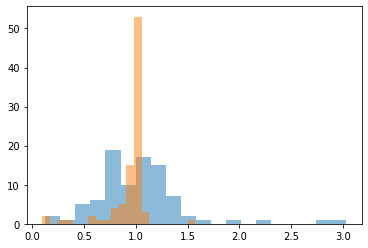

In [19]:
unif_1 = all_data[cells_1].sum(axis = 1)/data["lengths"]
unif_2 = all_data[cells_2].sum(axis = 1)/data["lengths"]
unif_1 = unif_1/np.median(unif_1)
unif_2 = unif_2/np.median(unif_2)
plt.hist(unif_1, bins = 20, alpha = 0.5)
plt.hist(unif_2, bins = 20, alpha = 0.5)

In [20]:
logmult_KV = np.log(mult_KV)
x , y  = logmult_KV[0], logmult_KV[1]

distances = np.abs(x - y) / np.sqrt(2)
sorted_indices = np.argsort(distances)[::-1]

top_n = 10
bottom_n = 30
top_indices = sorted_indices[:top_n]
bottom_indices = sorted_indices[-bottom_n:]

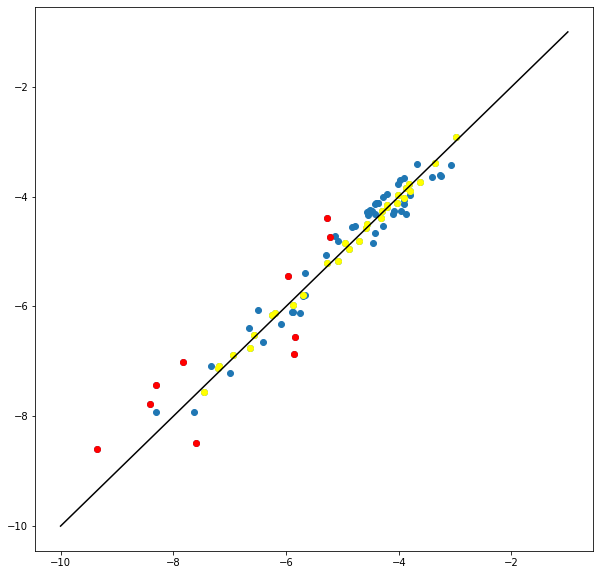

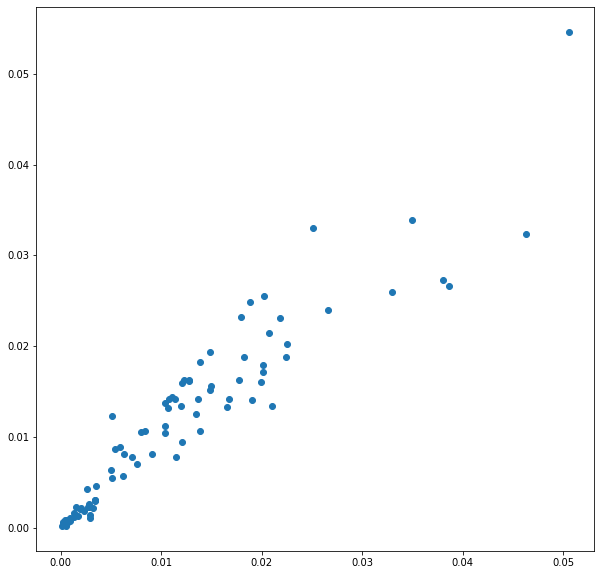

In [21]:
fig,ax = plt.subplots(1, figsize=(10, 10))
plt.scatter(logmult_KV[0], logmult_KV[1])
plt.scatter(x[top_indices], y[top_indices], color='red', label='Most different')
plt.scatter(x[bottom_indices], y[bottom_indices], color='yellow', label='Most alike')

plt.plot(range(-10,0), range(-10,0), color = "black", )
fig,ax = plt.subplots(1, figsize=(10, 10))
plt.scatter(mult_KV[0], mult_KV[1])

In [22]:
counts_1 = all_data[cells_1].sum(axis = 1)
counts_2 = all_data[cells_2].sum(axis = 1)

In [23]:
ratios_1 = []
ratios_2 = []
for i in top_indices:
    for j in bottom_indices:
        print(i,j)
        
        ratios_1.append(counts_1[i]/counts_1[j])
        ratios_2.append(counts_2[i]/counts_2[j])

56 35
56 70
56 18
56 41
56 7
56 17
56 19
56 69
56 80
56 15
56 16
56 32
56 64
56 66
56 12
56 74
56 65
56 85
56 30
56 76
56 61
56 88
56 48
56 36
56 81
56 5
56 33
56 57
56 23
56 26
54 35
54 70
54 18
54 41
54 7
54 17
54 19
54 69
54 80
54 15
54 16
54 32
54 64
54 66
54 12
54 74
54 65
54 85
54 30
54 76
54 61
54 88
54 48
54 36
54 81
54 5
54 33
54 57
54 23
54 26
21 35
21 70
21 18
21 41
21 7
21 17
21 19
21 69
21 80
21 15
21 16
21 32
21 64
21 66
21 12
21 74
21 65
21 85
21 30
21 76
21 61
21 88
21 48
21 36
21 81
21 5
21 33
21 57
21 23
21 26
52 35
52 70
52 18
52 41
52 7
52 17
52 19
52 69
52 80
52 15
52 16
52 32
52 64
52 66
52 12
52 74
52 65
52 85
52 30
52 76
52 61
52 88
52 48
52 36
52 81
52 5
52 33
52 57
52 23
52 26
9 35
9 70
9 18
9 41
9 7
9 17
9 19
9 69
9 80
9 15
9 16
9 32
9 64
9 66
9 12
9 74
9 65
9 85
9 30
9 76
9 61
9 88
9 48
9 36
9 81
9 5
9 33
9 57
9 23
9 26
45 35
45 70
45 18
45 41
45 7
45 17
45 19
45 69
45 80
45 15
45 16
45 32
45 64
45 66
45 12
45 74
45 65
45 85
45 30
45 76
45 61
45 88
45 48
45 

(0.0, 2.0)

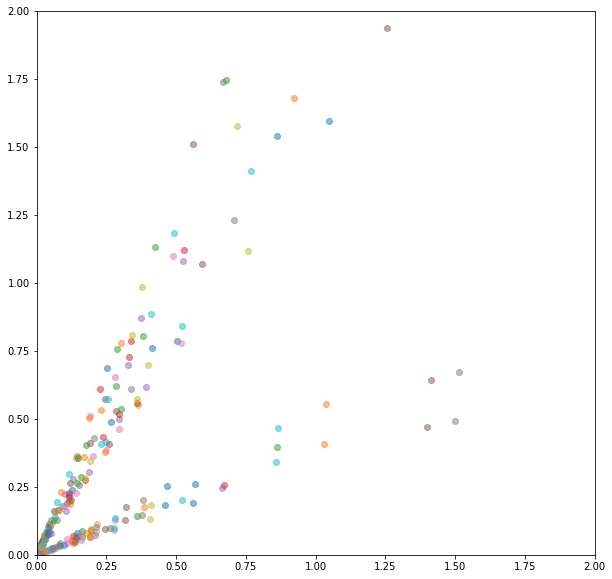

In [24]:
fig,ax = plt.subplots(1, figsize=(10, 10))
for r1, r2 in zip(ratios_1, ratios_2): 
#    fig,ax = plt.subplots(1, figsize=(10, 10))
    plt.scatter(r1, r2, alpha = 0.5)
plt.xlim([0,2])
plt.ylim([0,2])


Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed


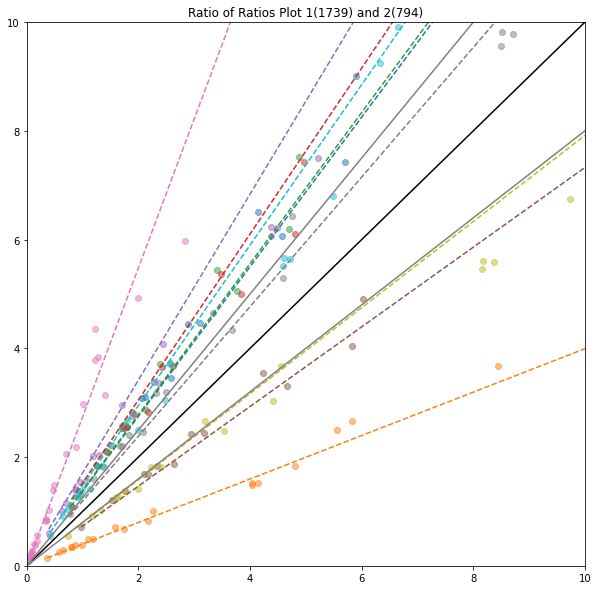

In [25]:

slopes, top_indices, bottom_indices, cells_1, cells_2, mult_KV = ratio_of_ratios(all_data)

(array([ 2.,  1.,  5.,  5., 19., 11., 17., 15.,  7.,  1.,  2.,  0.,  1.,
         0.,  1.,  0.,  0.,  0.,  1.,  1.]),
 array([0.12412223, 0.26926174, 0.41440125, 0.55954076, 0.70468027,
        0.84981978, 0.99495929, 1.1400988 , 1.28523831, 1.43037782,
        1.57551733, 1.72065684, 1.86579635, 2.01093586, 2.15607537,
        2.30121488, 2.44635439, 2.5914939 , 2.73663341, 2.88177292,
        3.02691243]),
 <BarContainer object of 20 artists>)

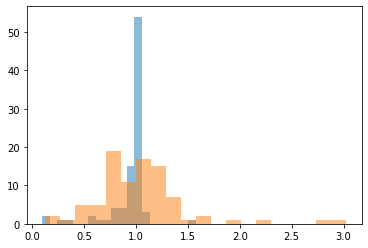

In [26]:
unif_1 = all_data[cells_1].sum(axis = 1)/data["lengths"]
unif_2 = all_data[cells_2].sum(axis = 1)/data["lengths"]
unif_1 = unif_1/np.median(unif_1)
unif_2 = unif_2/np.median(unif_2)
plt.hist(unif_1, bins = 20, alpha = 0.5)
plt.hist(unif_2, bins = 20, alpha = 0.5)

In [27]:
new_data1 = all_data[cells_1]
new_data2 = all_data[cells_2]

Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed


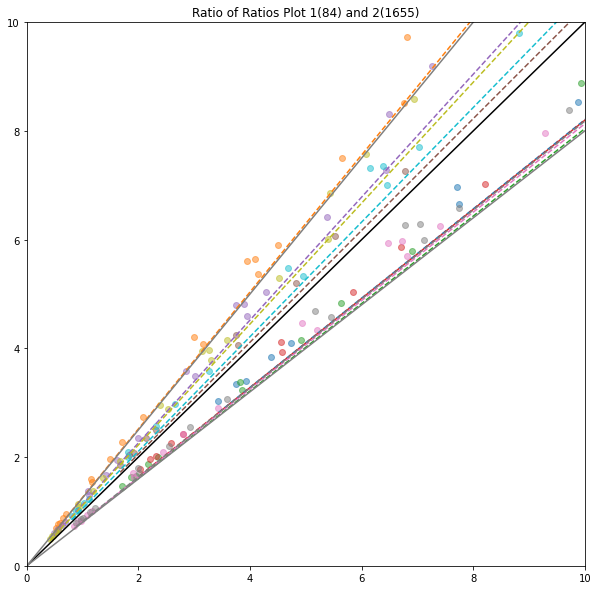

In [28]:
slopes1, top_indices1, bottom_indices1, cells_11, cells_12, mult_KV = ratio_of_ratios(new_data1)

(array([ 2.,  0.,  1.,  1.,  0.,  0.,  2.,  1.,  1.,  4.,  4., 15., 55.,
         2.,  0.,  0.,  0.,  0.,  0.,  1.]),
 array([0.09278727, 0.16709587, 0.24140447, 0.31571308, 0.39002168,
        0.46433029, 0.53863889, 0.6129475 , 0.6872561 , 0.76156471,
        0.83587331, 0.91018191, 0.98449052, 1.05879912, 1.13310773,
        1.20741633, 1.28172494, 1.35603354, 1.43034215, 1.50465075,
        1.57895936]),
 <BarContainer object of 20 artists>)

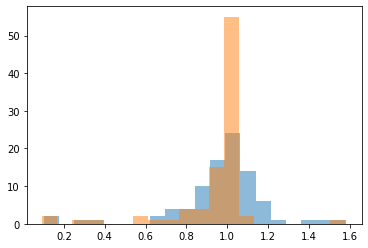

In [29]:
unif_1 = all_data[cells_11].sum(axis = 1)/data["lengths"]
unif_2 = all_data[cells_12].sum(axis = 1)/data["lengths"]
unif_1 = unif_1/np.median(unif_1)
unif_2 = unif_2/np.median(unif_2)
plt.hist(unif_1, bins = 20, alpha = 0.5)
plt.hist(unif_2, bins = 20, alpha = 0.5)

In [30]:
sorted((max(slopes1), min(slopes1), 4/5, 5/4))

[0.8, 0.8041458285357381, 1.25, 1.2595336222767248]

Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed


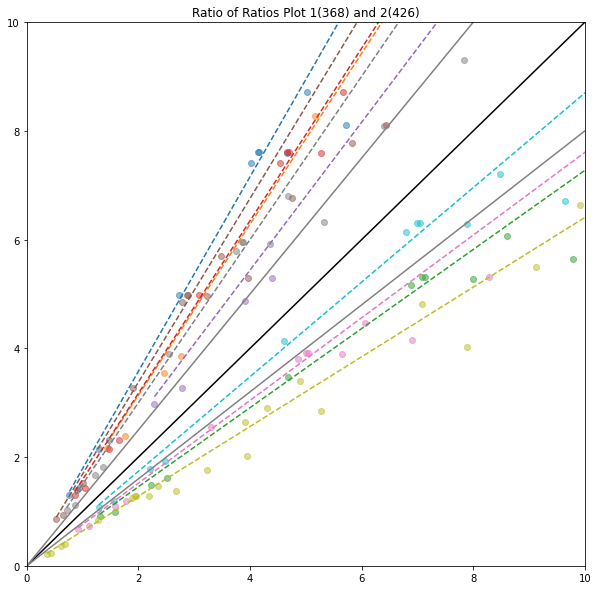

In [31]:
slopes2, top_indices2, bottom_indices2, cells_21, cells_22, mult_KV = ratio_of_ratios(new_data2)

(array([ 2.,  1.,  6.,  4., 22.,  6., 11., 16.,  9.,  7.,  1.,  0.,  1.,
         1.,  0.,  0.,  0.,  1.,  0.,  1.]),
 array([0.11049222, 0.24507888, 0.37966553, 0.51425218, 0.64883884,
        0.78342549, 0.91801214, 1.05259879, 1.18718545, 1.3217721 ,
        1.45635875, 1.59094541, 1.72553206, 1.86011871, 1.99470537,
        2.12929202, 2.26387867, 2.39846533, 2.53305198, 2.66763863,
        2.80222529]),
 <BarContainer object of 20 artists>)

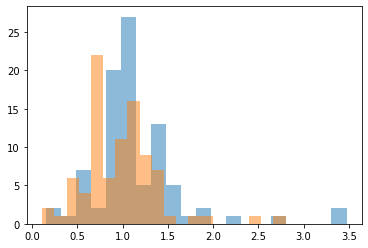

In [32]:
unif_1 = all_data[cells_21].sum(axis = 1)/data["lengths"]
unif_2 = all_data[cells_22].sum(axis = 1)/data["lengths"]
unif_1 = unif_1/np.median(unif_1)
unif_2 = unif_2/np.median(unif_2)
plt.hist(unif_1, bins = 20, alpha = 0.5)
plt.hist(unif_2, bins = 20, alpha = 0.5)

In [33]:
sorted((max(slopes2), min(slopes2), 0.7, 1/0.7))

[0.6407503861265336, 0.7, 1.4285714285714286, 1.789223453357136]

In [34]:
# def recursive_em_split(data, cell_list, threshold=3/4, max_depth=10, current_depth=0, name="A"):
#     """
#     Recursively splits cell populations using EM algorithm until slopes are within threshold.
    
#     Parameters:
#     - data: the full genomic data
#     - cell_list: list of cells in current population
#     - threshold: minimum slope threshold (splits rejected if slopes between threshold and 1/threshold)
#     - max_depth: maximum recursion depth
#     - current_depth: current recursion level
#     - name: name/identifier for current population
    
#     Returns:
#     - Dictionary containing the tree structure with final populations
#     """
    
#     print(f"{'  ' * current_depth}Processing population {name} with {len(cell_list)} cells")
    
#     # Base cases
#     threshold = min(threshold, 1/threshold)
#     if current_depth >= max_depth:
#         print(f"{'  ' * current_depth}Max depth reached for {name}")
#         return {name: cell_list}
    
#     if len(cell_list) < 50:  # Minimum population size
#         print(f"{'  ' * current_depth}Population {name} too small to split")
#         return {name: cell_list}
    
#     # Try to split the population
#     try:
#         current_data = data[cell_list]
#         slopes, top_indices, bottom_indices, cells_1, cells_2, mult_KV = ratio_of_ratios(current_data, threshold, name)
#         # Check if split should be rejected based on slope criteria
#         max_slope = max(slopes)
#         min_slope = min(slopes)
        
#         print(f"{'  ' * current_depth}Slopes for {name}: max={max_slope:.3f}, min={min_slope:.3f}")
        
#         # Reject split if slopes are between threshold and 1/threshold
#         if threshold <= min_slope and max_slope <= 1/threshold:
#             print(f"{'  ' * current_depth}Split rejected for {name}: slopes between {threshold:.3f} and {1/threshold:.3f}")
#             return {name: cell_list}
        
#         # Check if we have valid splits
#         if len(cells_1) < 25 or len(cells_2) < 25:
#             print(f"{'  ' * current_depth}Split produces too small subpopulations for {name}")
#             return {name: cell_list}
        
#         print(f"{'  ' * current_depth}Split accepted for {name}: {len(cells_1)} + {len(cells_2)} cells")
        
#         # Recursively split both subpopulations
#         result = {}
        
#         # Split first subpopulation
#         sub_result_1 = recursive_em_split(
#             data, cells_1, threshold, max_depth, current_depth + 1, name + "1"
#         )
#         result.update(sub_result_1)
        
#         # Split second subpopulation  
#         sub_result_2 = recursive_em_split(
#             data, cells_2, threshold, max_depth, current_depth + 1, name + "2"
#         )
#         result.update(sub_result_2)
        
#         return result
        
#     except Exception as e:
#         print(f"{'  ' * current_depth}Error splitting {name}: {e}")
#         return {name: cell_list}


In [35]:
q_data = all_data/all_data.sum(axis=0)
mult_KV_param = q_data.mean(axis=1).values

Processing population A with 2533 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Slopes for A: max=2.537, min=0.328
Split accepted for A: 790 + 1743 cells
  Processing population A1 with 790 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
  Slopes for A1: max=1.778, min=0.641
  Split accepted for A1: 365 + 425 cells
    Processing population A11 with 365 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
    Slopes for A11: max=1.101, min=0.716
    Split accepted for A11: 145 + 220 cells
      Processing population A111 with 145 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new 

/home/ranade/.local/lib/python3.6/site-packages/ipykernel_launcher.py:14: RuntimeWarning: divide by zero encountered in log
  


Trying new seed
      Slopes for A121: max=1.806, min=0.711
      Split produces too small subpopulations for A121
      Processing population A122 with 334 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
      Slopes for A122: max=1.237, min=0.662
      Split accepted for A122: 80 + 254 cells
        Processing population A1221 with 80 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
        Slopes for A1221: max=1.384, min=0.631
        Split accepted for A1221: 43 + 37 cells
          Processing population A12211 with 43 cells
          Population A12211 too small to split
          Processing population A12212 with 37 cells
          Population A12212 too small to split
        Processing population A1222 with 254 cells
Trying new seed
Trying new seed

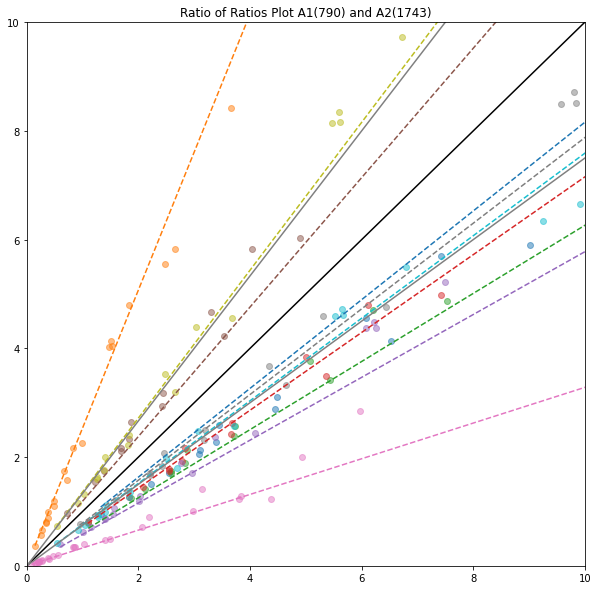

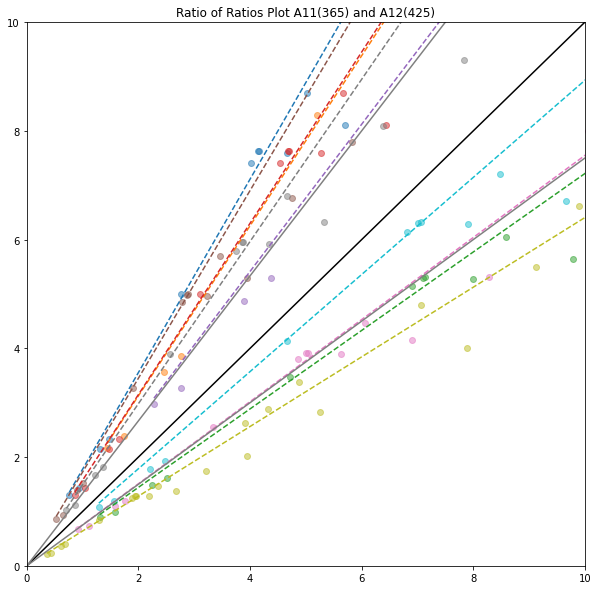

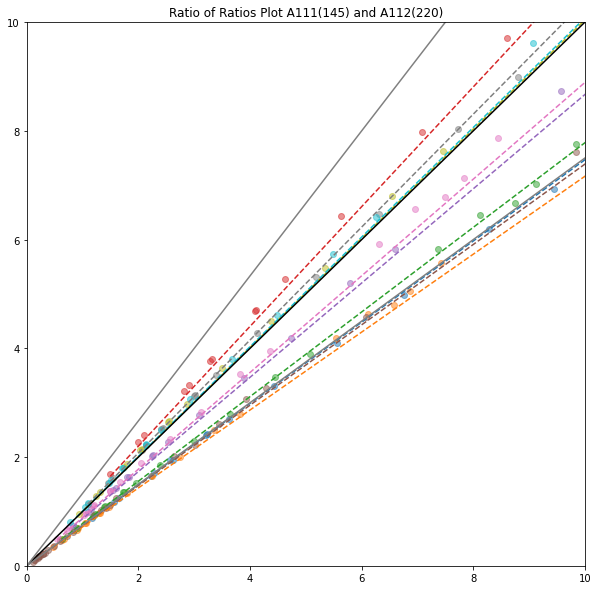

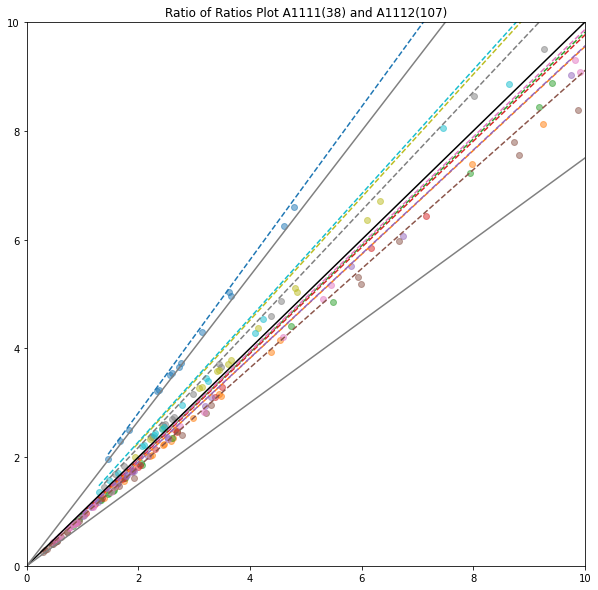

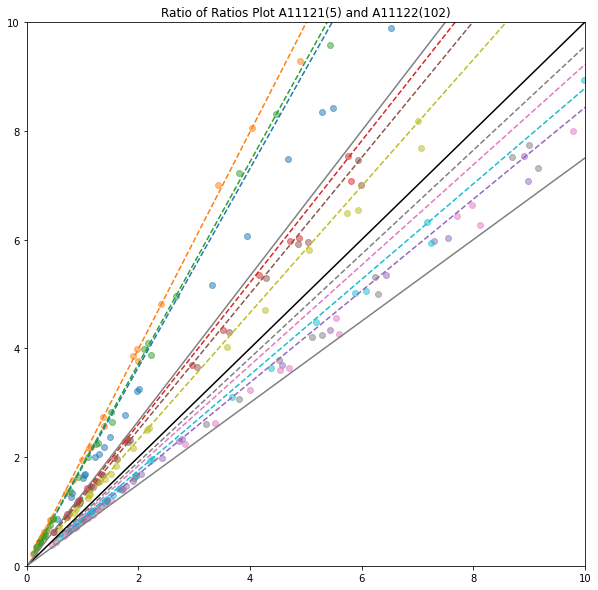

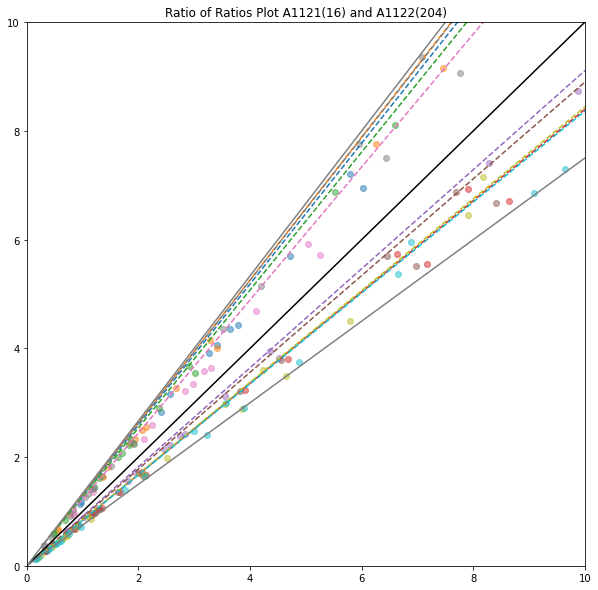

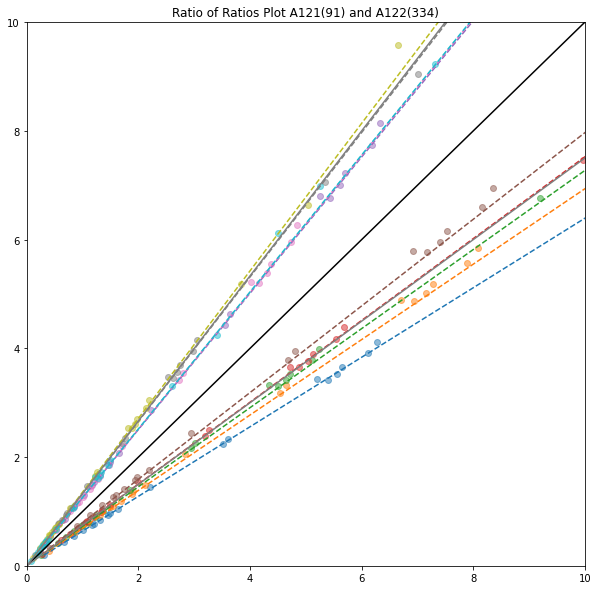

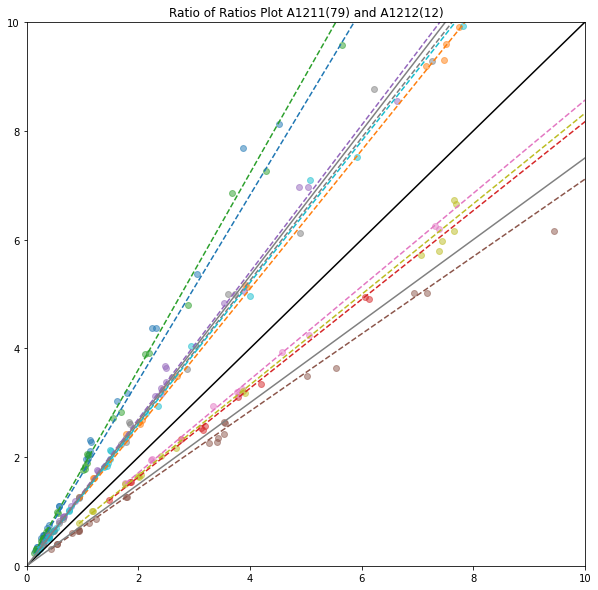

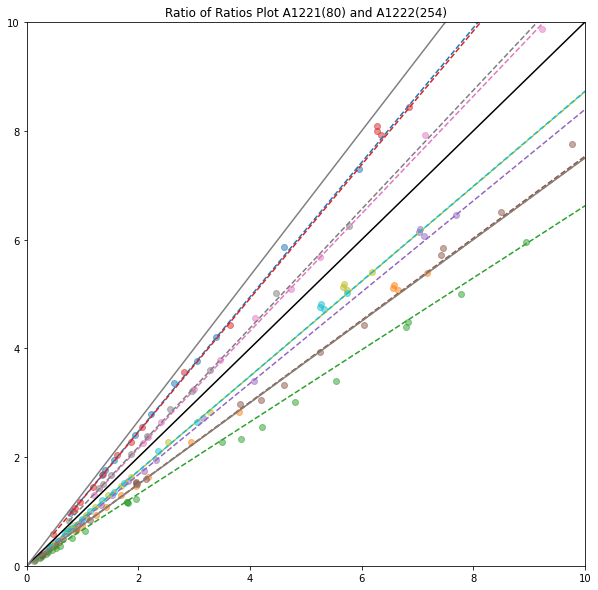

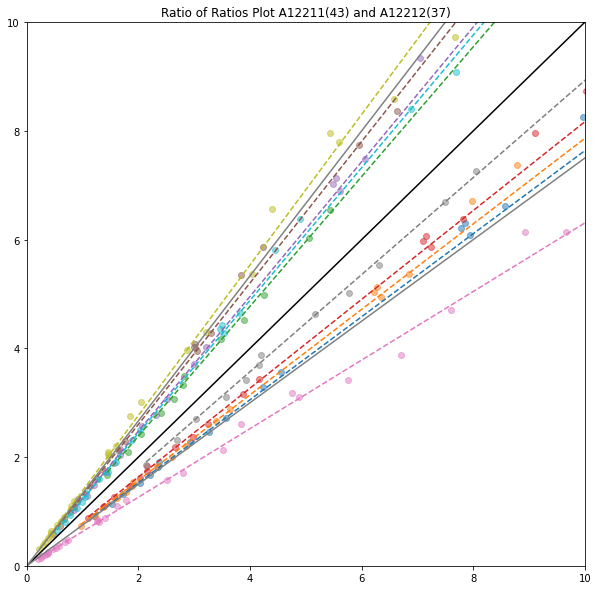

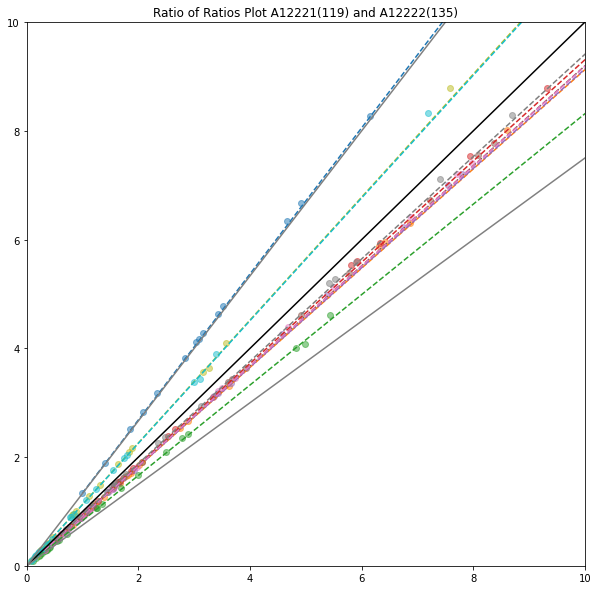

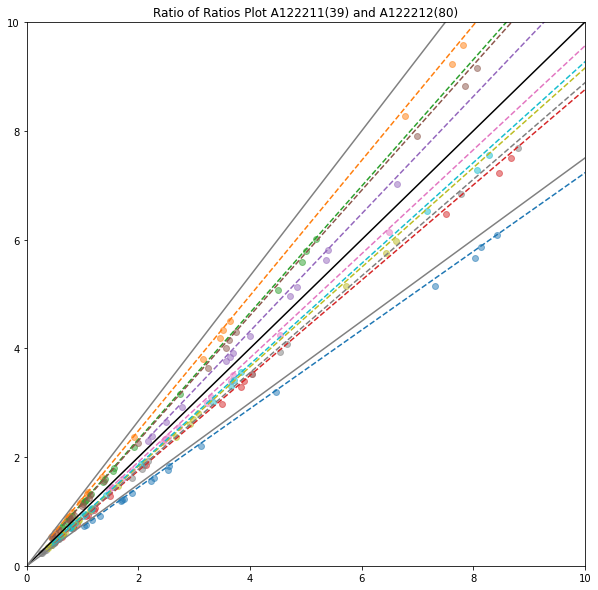

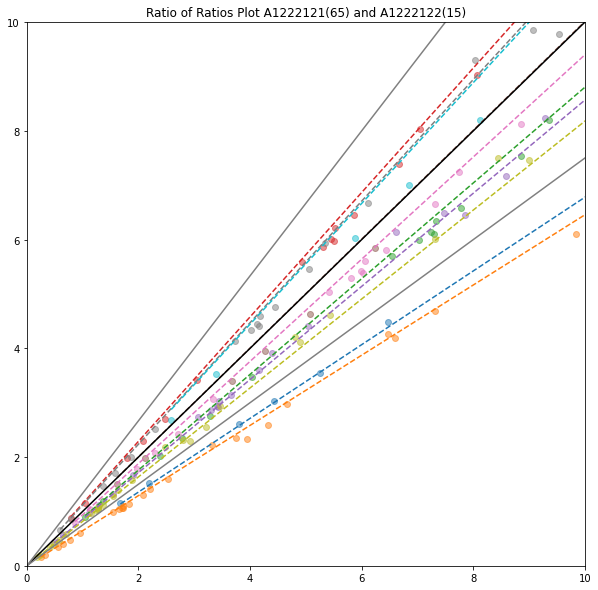

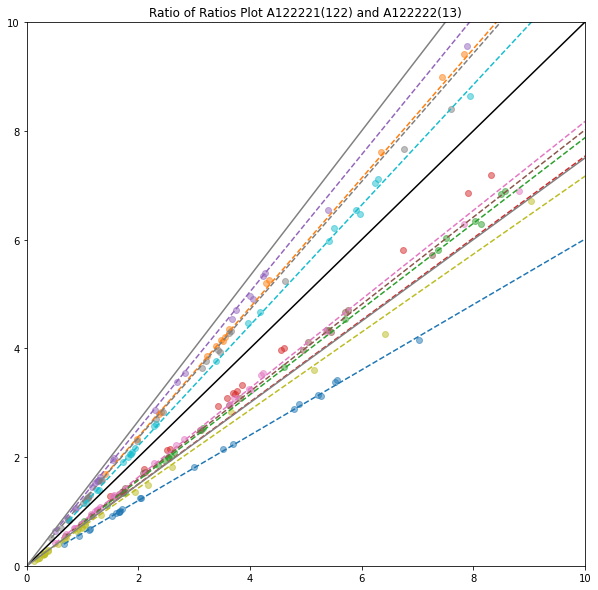

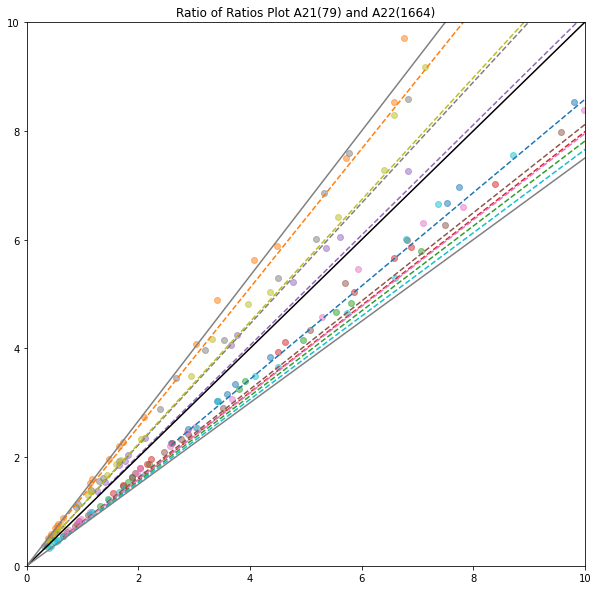

In [36]:
final_populations = recursive_em_split(all_data, cells,threshold=3/4, max_depth=10, current_depth=0, name="A")

In [37]:
len(final_populations)

10

In [38]:
print(final_populations.keys())

dict_keys(['A1111', 'A1112', 'A112', 'A121', 'A12211', 'A12212', 'A122211', 'A122212', 'A12222', 'A2'])


In [39]:
for A in final_populations:
    print(A, len(final_populations[A]["cells"]))

A1111 38
A1112 107
A112 220
A121 91
A12211 43
A12212 37
A122211 39
A122212 80
A12222 135
A2 1743


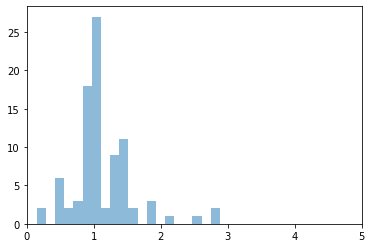

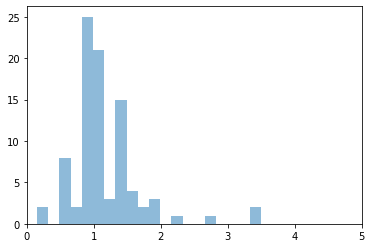

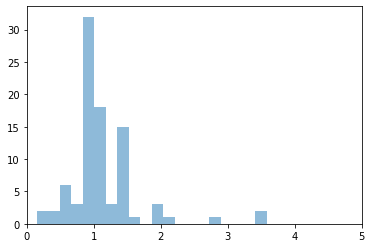

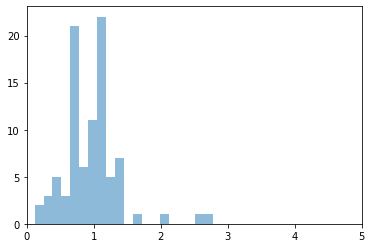

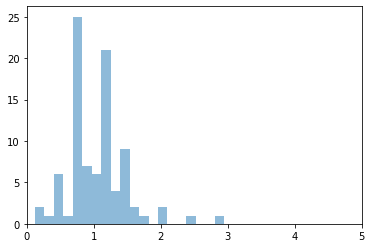

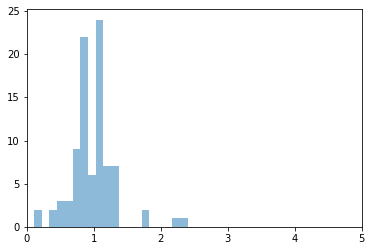

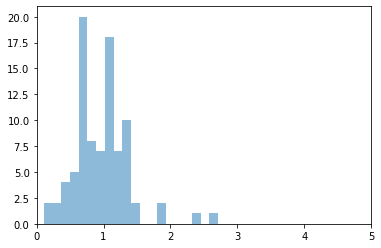

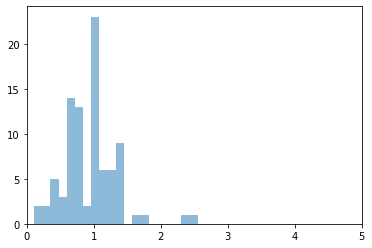

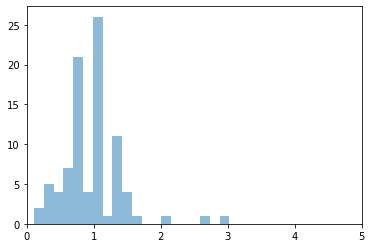

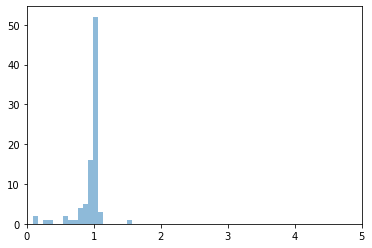

In [40]:
#Check for uniformity accross segments in each population
dev_from_median = {}
unif_dict = {}
for pop in final_populations:
    pop_cells = final_populations[pop]["cells"]
    pop_data = all_data[pop_cells]
    unif = pop_data.sum(axis = 1)/data["lengths"]
    unif = unif/np.median(unif)
    plt.hist(unif, bins = 20, alpha = 0.5, label = pop)
    plt.xlim([0,5])
    dev_from_median[pop] = np.median(np.abs(unif - 1))
    #plt.title(f"Population {pop} with {len(pop_cells)} cells")
    plt.show()

In [41]:
normal_cells = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/normal_cells.txt", header = None,sep = "\t")[0].values



In [42]:
# Population with least deviation from median is likely normal
# Let us pick this population as normal
min_dev_pop = min(dev_from_median, key=dev_from_median.get)

In [43]:
# Check overlap with known normal cells
print(len([c for c in final_populations[min_dev_pop]["cells"] if c in normal_cells]))
len(final_populations[min_dev_pop]["cells"]), len(normal_cells)

1623


(1743, 1623)

Processing population B with 2533 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Slopes for B: max=2.413, min=0.372
Split accepted for B: 790 + 1743 cells
  Processing population B1 with 790 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
  Slopes for B1: max=1.778, min=0.641
  Split accepted for B1: 365 + 425 cells
    Processing population B11 with 365 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
    Slopes for B11: max=1.385, min=0.903
    Split accepted for B11: 219 + 146 cells
      Processing population B111 with 219 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new 

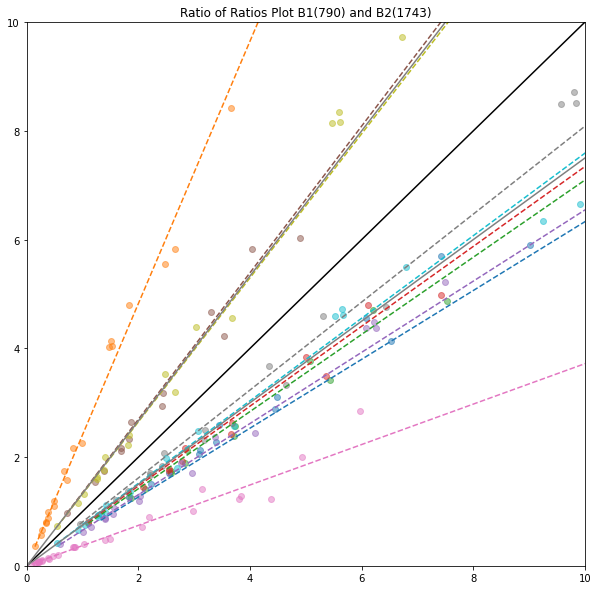

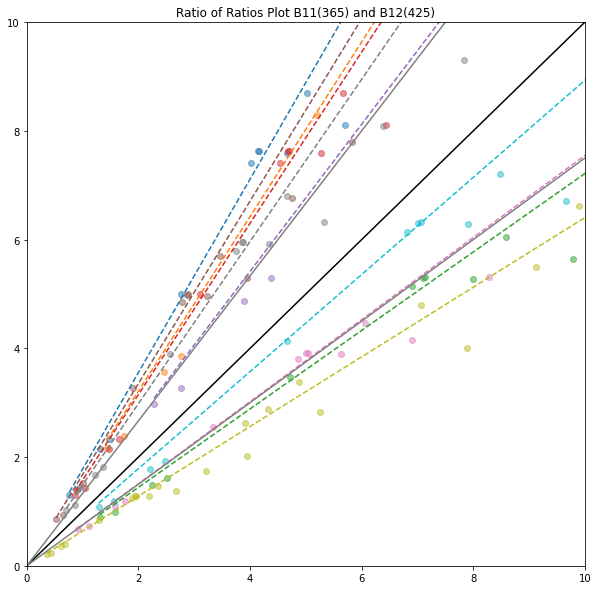

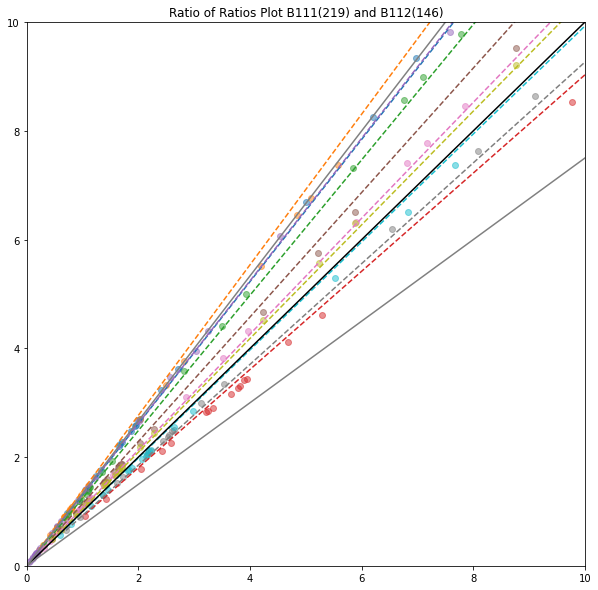

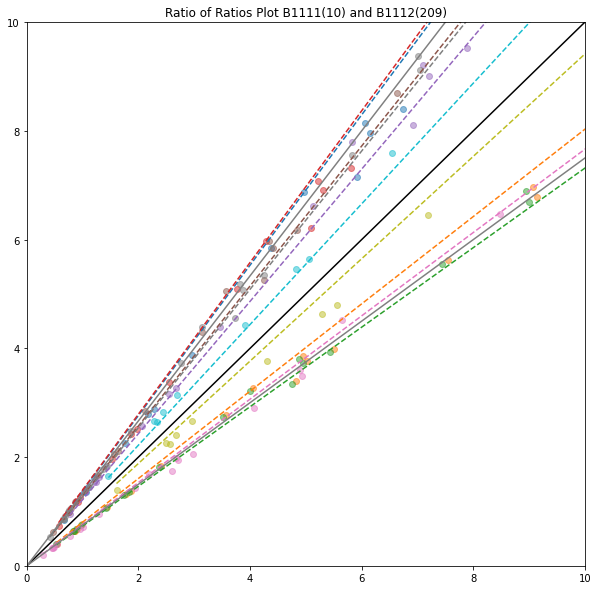

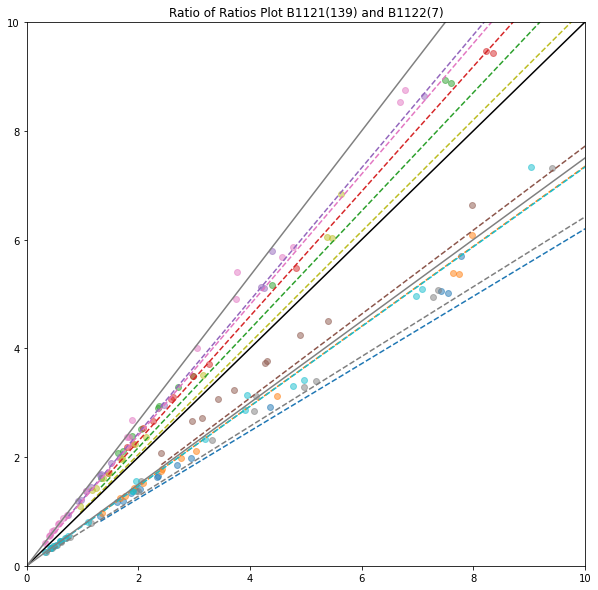

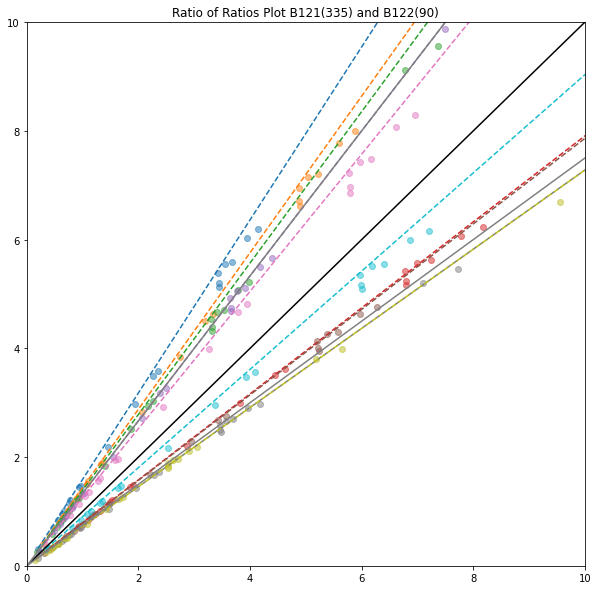

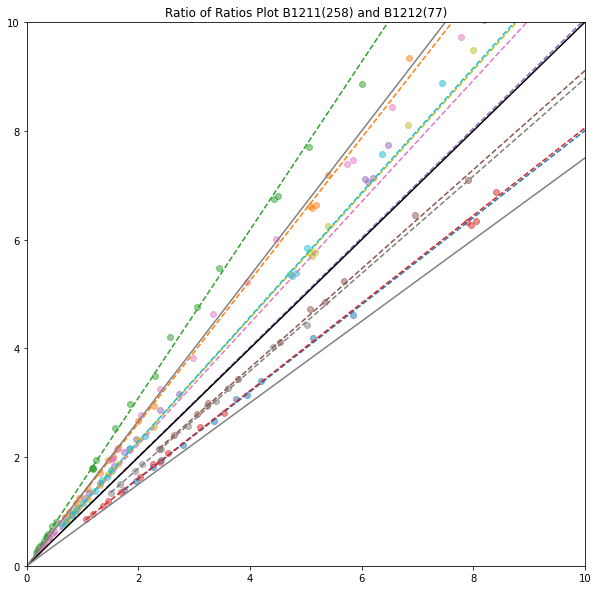

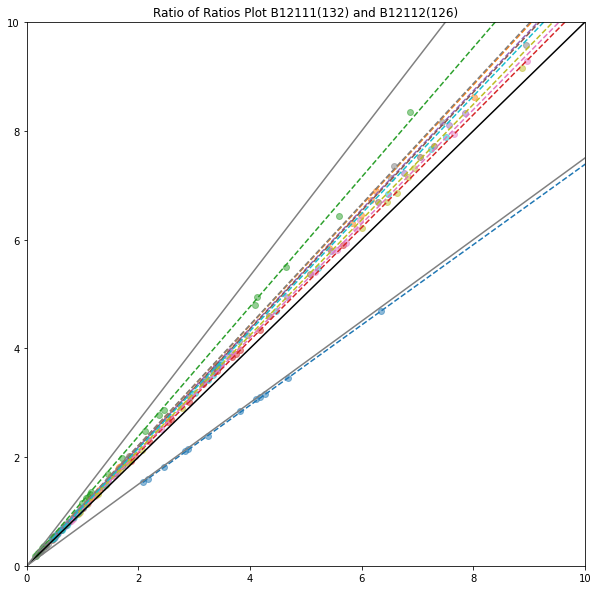

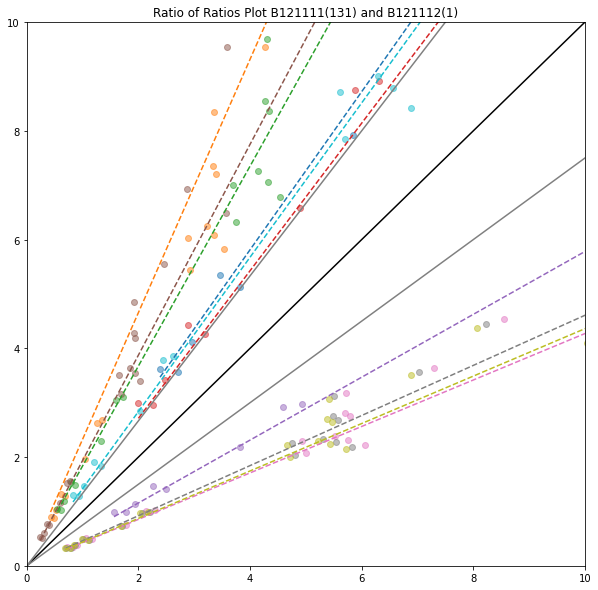

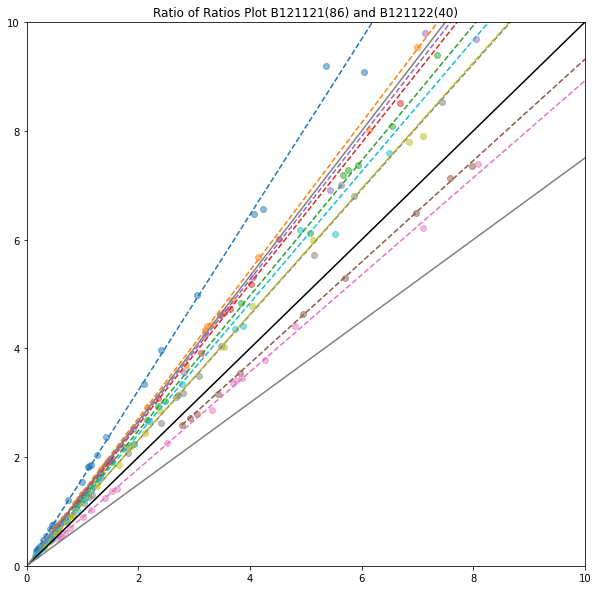

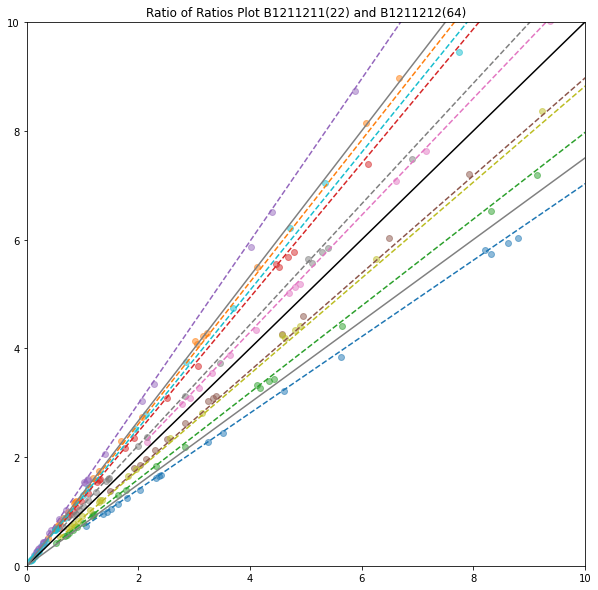

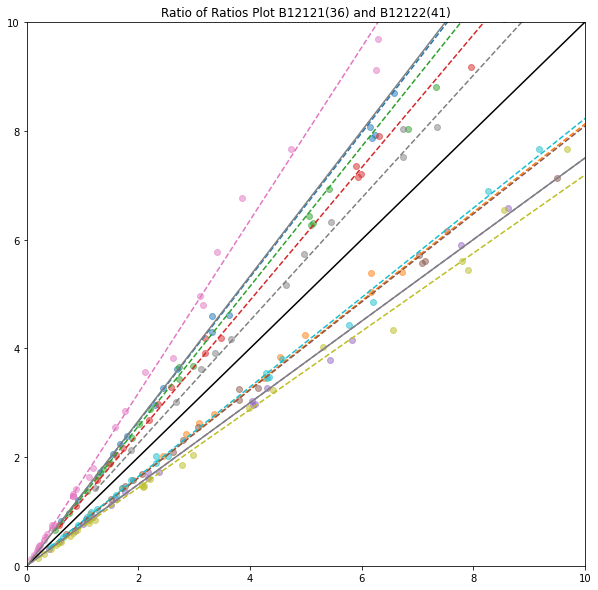

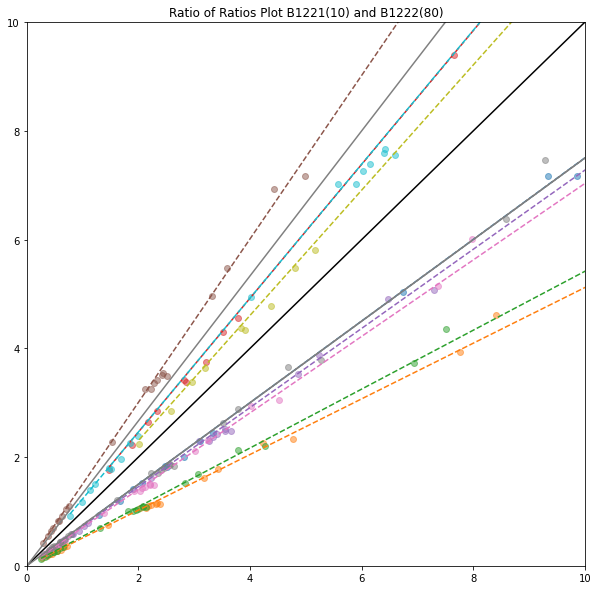

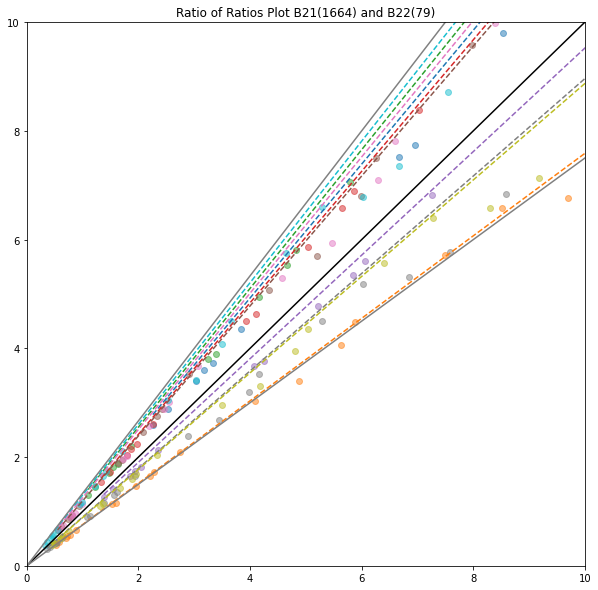

In [44]:
final_populations_2 = recursive_em_split(all_data, cells,threshold=3/4, max_depth=10, current_depth=0, name="B")

In [45]:
for B in final_populations_2:
    print(B, len(final_populations_2[B]["cells"]))

B111 219
B112 146
B12111 132
B121121 86
B121122 40
B12121 36
B12122 41
B122 90
B2 1743


In [46]:
for A in final_populations:
    print(A, len(final_populations[A]["cells"]))

A1111 38
A1112 107
A112 220
A121 91
A12211 43
A12212 37
A122211 39
A122212 80
A12222 135
A2 1743


In [47]:
from scipy.special import logsumexp
#Reassign cells to populations based on closest multinomial parameters
def reassign_cells(data, populations):
    """
    Reassigns cells to populations based on closest multinomial parameters.
    
    Parameters:
    - data: the full genomic data
    - populations: dictionary of populations with their cells and mult_KV parameters
    
    Returns:
    - Dictionary with updated cell assignments for each population
    """
    
    # Extract multinomial parameters for each population
    pop_params = {pop: populations[pop]['mult_KV'] for pop in populations}
    
    # Prepare a new dictionary to hold reassigned cells
    new_populations = {pop: {"cells": [], "mult_KV": populations[pop]["mult_KV"]} for pop in populations}

    # Iterate over each cell in the data
    for cell in data.columns:
        cell_data = data[cell].values
        # Compute log-likelihoods for the cell under each population's multinomial parameters
        log_likelihoods = {}
        for pop, params in pop_params.items():
            log_probs = np.log(params + 1e-10)  # Add small value to avoid log(0)
            log_likelihood = np.sum(cell_data * log_probs)
            log_likelihoods[pop] = log_likelihood
        # Subtract max log-likelihood for numerical stability   
        max_log_likelihood = max(log_likelihoods.values())
        for pop in log_likelihoods:
            log_likelihoods[pop] -= max_log_likelihood
        # Assign the cell to the population with the highest log-likelihood
        best_pop = max(log_likelihoods, key=log_likelihoods.get)
        new_populations[best_pop]["cells"].append(cell)

    

    return new_populations
reassigned_populations = reassign_cells(all_data, final_populations)
reassigned_populations_2 = reassign_cells(all_data, final_populations_2)

In [48]:
def print_overlap_matrix(pop1, pop2, name1="A", name2="B"):
    """
    Print overlap matrix showing number of shared cells between populations
    """
    pop1_names = sorted(pop1.keys())
    pop2_names = sorted(pop2.keys())
    
    # Print header
    print(f"\nOverlap Matrix ({name1} rows vs {name2} cols):")
    print("=" * 50)
    print(f"{'Pop':<8}", end="")
    for pop_b in pop2_names:
        print(f"{pop_b:>8}", end="")
    print()
    
    # Print overlap counts
    for pop_a in pop1_names:
        cells_a = set(pop1[pop_a]["cells"])
        print(f"{pop_a:<8}", end="")
        
        for pop_b in pop2_names:
            cells_b = set(pop2[pop_b]["cells"])
            overlap = len(cells_a.intersection(cells_b))
            print(f"{overlap:>8}", end="")
        print()

In [49]:
print_overlap_matrix(reassigned_populations, reassigned_populations_2, "A", "B")


Overlap Matrix (A rows vs B cols):
Pop         B111    B112  B12111 B121121 B121122  B12121  B12122    B122      B2
A1111          1      36       0       0       0       3       0       0       3
A1112          1     106       0       0       0       0       0       0       0
A112         221       2       0       0       0       0       0       0       0
A121           0       0       1       0       2       0       0      80       0
A12211         0       0       1       0       0       0      38       0       0
A12212         1       0       0       0       4      52       0       0       0
A122211        0       0       0      28      18       1       1       1       0
A122212        0       0       2      61      21       0       0       0       0
A12222         0       0     125       2       5       0       0       0       0
A2             0       0       0       0       0       0       0       0    1716


In [50]:
print_overlap_matrix(reassigned_populations, final_populations, "newA", "oldA")


Overlap Matrix (newA rows vs oldA cols):
Pop        A1111   A1112    A112    A121  A12211  A12212 A122211 A122212  A12222      A2
A1111         38       0       0       0       0       0       0       0       0       5
A1112          0     107       0       0       0       0       0       0       0       0
A112           0       0     217       0       0       0       0       0       0       6
A121           0       0       0      83       0       0       0       0       0       0
A12211         0       0       0       0      38       0       0       0       1       0
A12212         0       0       3       5       0      33       0       0       0      16
A122211        0       0       0       3       2       4      39       0       1       0
A122212        0       0       0       0       3       0       0      79       2       0
A12222         0       0       0       0       0       0       0       1     131       0
A2             0       0       0       0       0       0       0    

In [51]:
# Save normal population cells
normal_population_cells = reassigned_populations[min_dev_pop]["cells"]
# with open(folder+tumor+".normal_cells_EM.txt", "w") as f:
#     for cell in normal_population_cells:
#         f.write(cell + "\n")

In [52]:
#Compare populations to normal population
def make_unif_dict(all_data, reassigned_populations):
    """
    Make uniformity dictionary for each population.
    """
    unif_dict = {}
    dev_from_median = {}
    for pop in reassigned_populations:
        pop_cells = reassigned_populations[pop]["cells"]
        pop_data = all_data[pop_cells]
        unif = pop_data.sum(axis = 1)/data["lengths"]
        unif = unif/np.median(unif)
        plt.hist(unif, bins = 20, alpha = 0.5, label = pop)
        plt.xlim([0,5])
        unif_dict[pop] = unif
        dev_from_median[pop] = np.median(np.abs(unif - 1))
        #plt.title(f"Population {pop} with {len(pop_cells)} cells")
        plt.show()
    min_dev_pop = min(dev_from_median, key=dev_from_median.get)
    return unif_dict, min_dev_pop

        




In [53]:
# Pairwise comparison of populations to find similar ones using unif_dict
def find_similar_populations(unif_dict):
    pop_names = list(unif_dict.keys())
    similar_populations = []
    for i in range(len(pop_names)):
        for j in range(i+1, len(pop_names)):
            pop_a = pop_names[i]
            pop_b = pop_names[j]
            
            unif_a = unif_dict[pop_a]
            unif_b = unif_dict[pop_b]
            ratio_unif = unif_a / unif_b
            
            fig, ax = plt.subplots(figsize=(6, 6))
            plt.scatter(unif_a, unif_b, alpha=0.5)
            plt.xlim([0, 5])
            plt.ylim([0, 5])
            plt.title(f"Uniformity Comparison: {pop_a} vs {pop_b}")
            plt.xlabel(f"Population {pop_a} Uniformity")
            plt.ylabel(f"Population {pop_b} Uniformity")
            plt.plot([0, 5], [0, 5], color='black', linestyle='dashed')  # y=x line
            plt.show()

            fig, ax = plt.subplots(figsize=(6, 6))
            plt.hist(ratio_unif, bins=30, alpha=0.7)
            plt.xlim([0, 5])
            plt.title(f"Ratio of Uniformities: {pop_a}/{pop_b}")
            plt.xlabel("Uniformity Ratio")
            plt.ylabel("Frequency")
            plt.show()
            # Check if populations are similar based on spread of ratio_unif
            if np.std(ratio_unif) < 0.1:  # Example threshold for similarity
                similar_populations.append((pop_a, pop_b))
                print(f"Populations {pop_a} and {pop_b} are similar.")

            
    return similar_populations

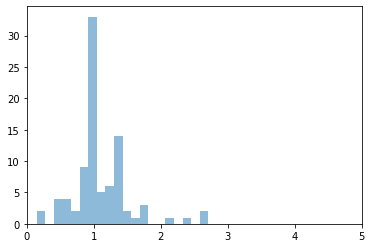

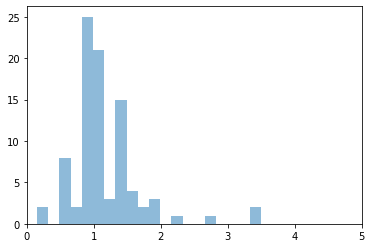

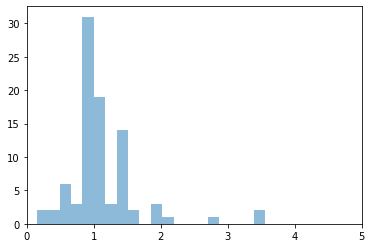

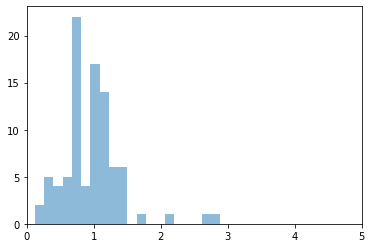

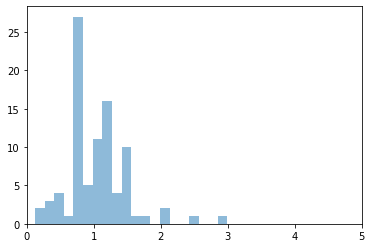

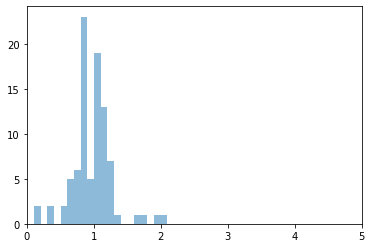

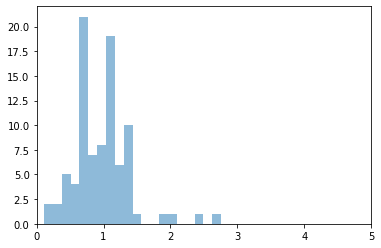

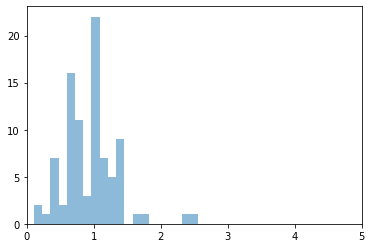

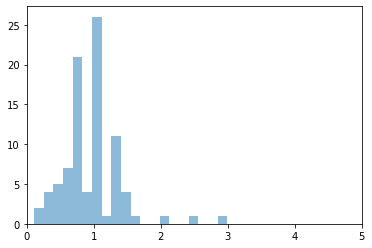

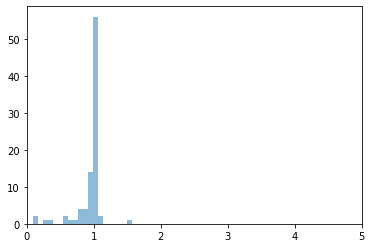

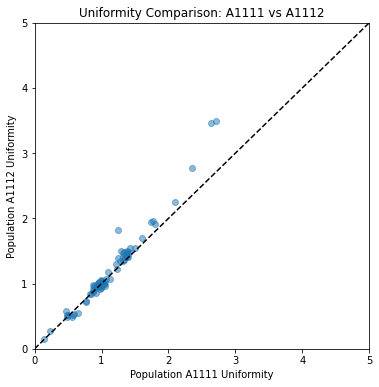

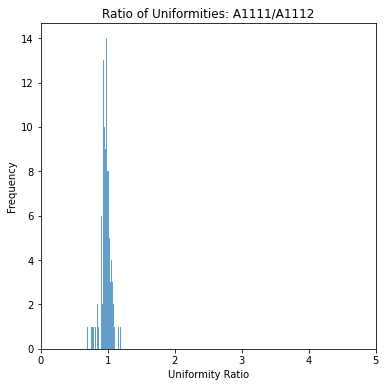

Populations A1111 and A1112 are similar.


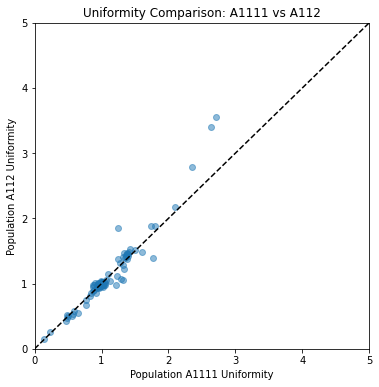

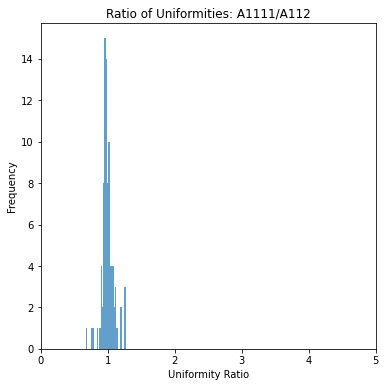

Populations A1111 and A112 are similar.


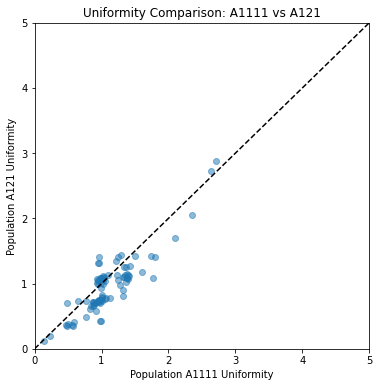

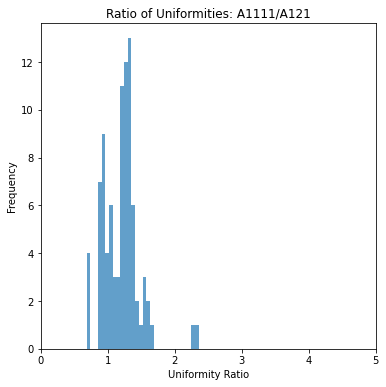

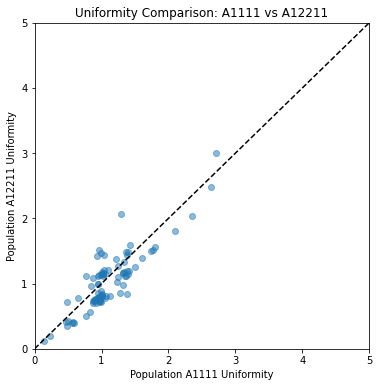

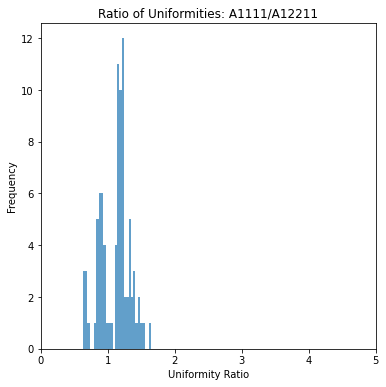

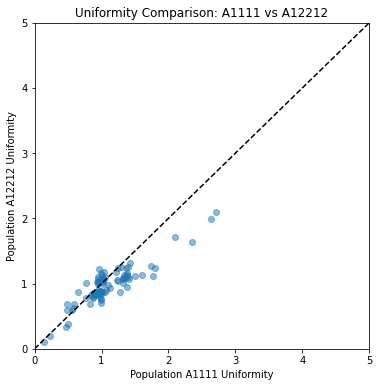

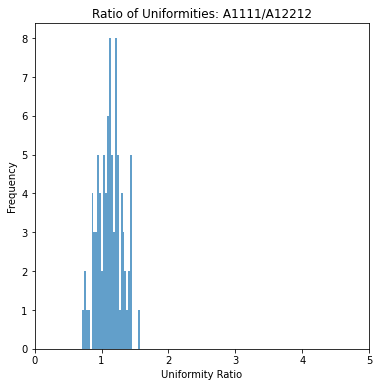

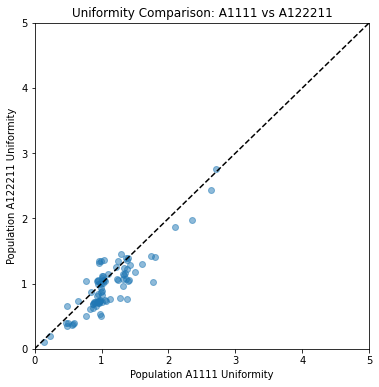

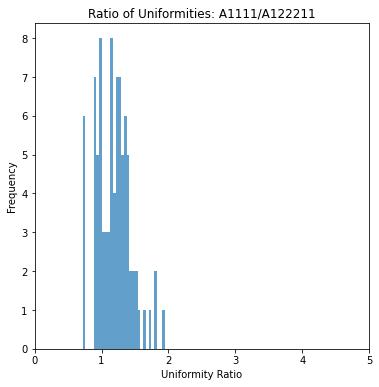

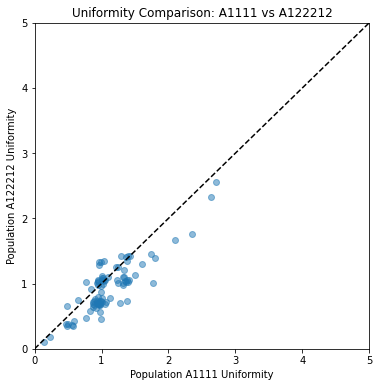

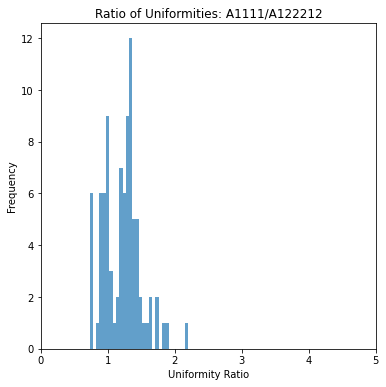

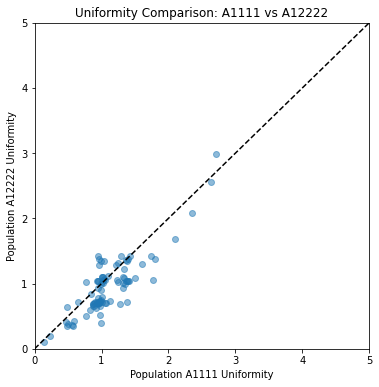

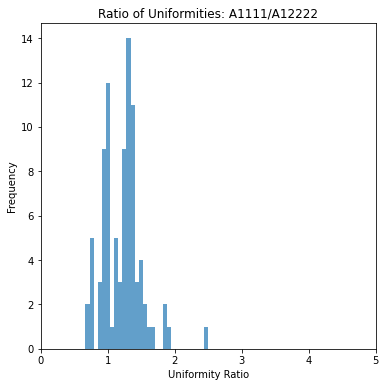

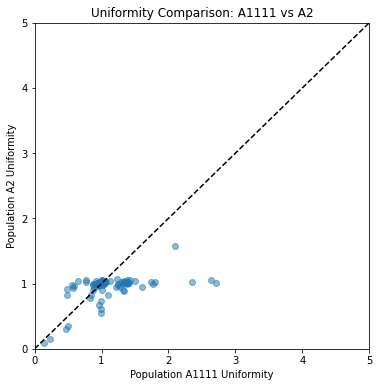

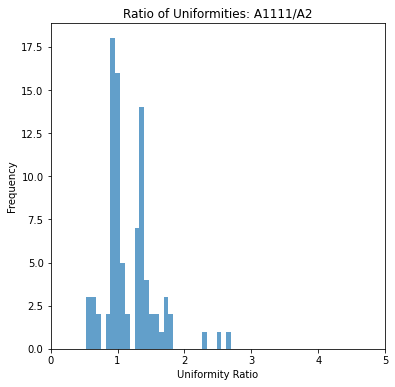

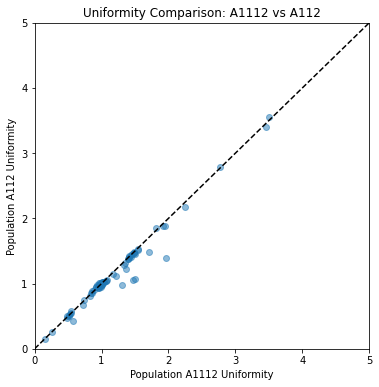

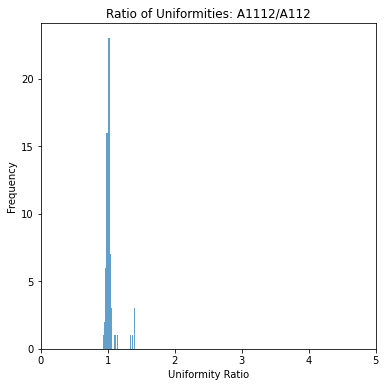

Populations A1112 and A112 are similar.


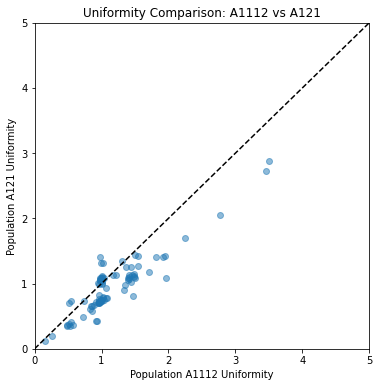

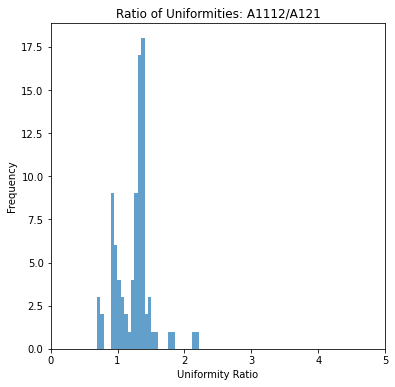

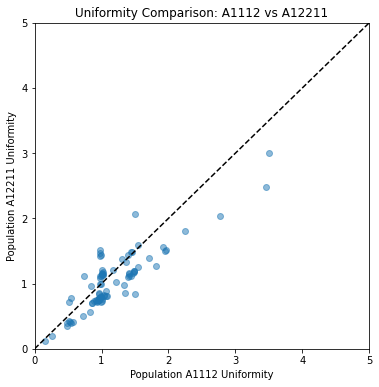

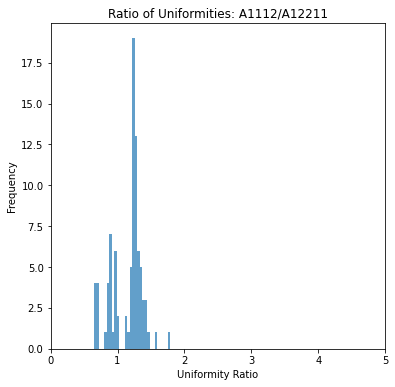

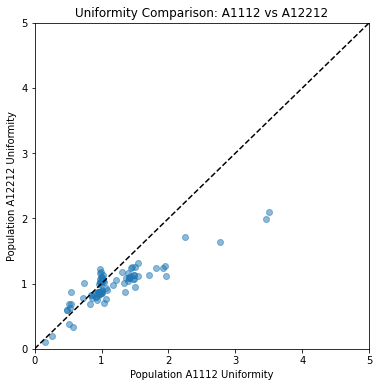

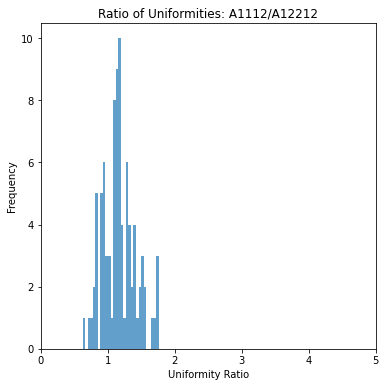

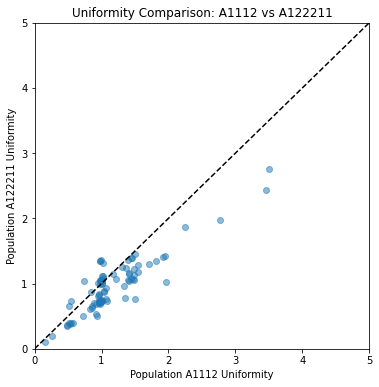

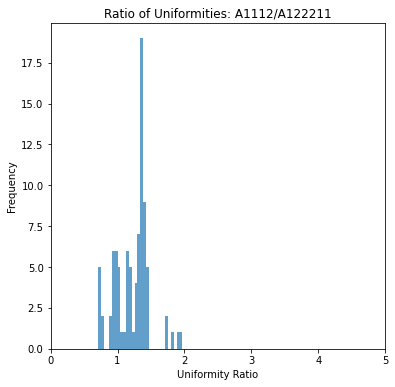

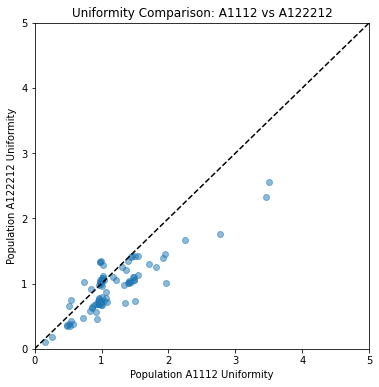

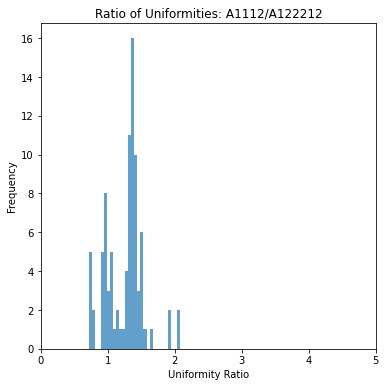

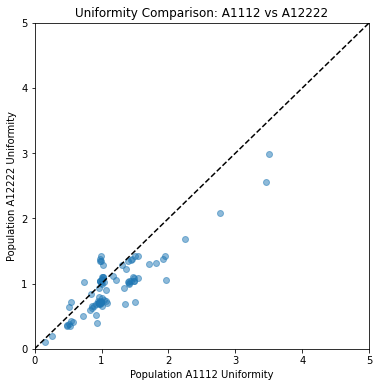

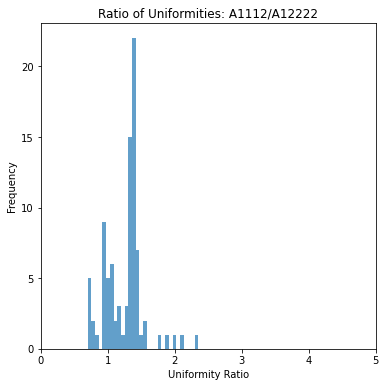

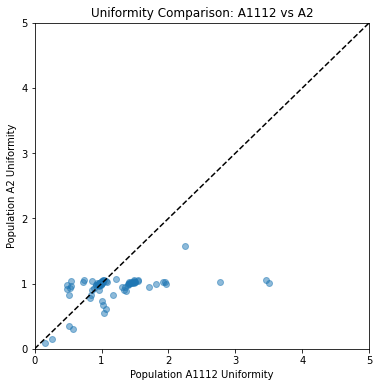

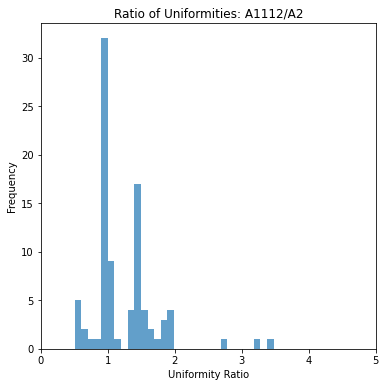

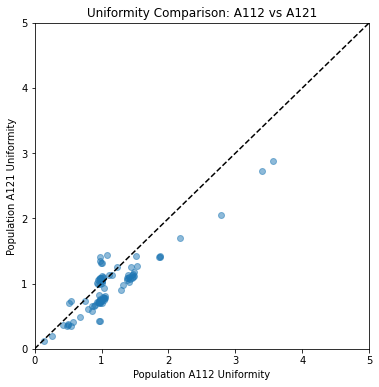

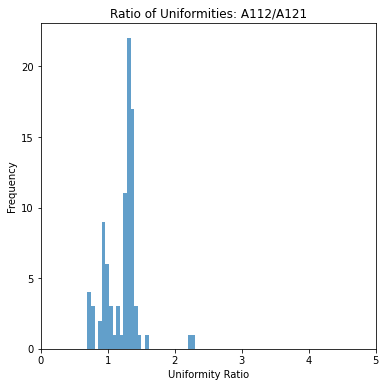

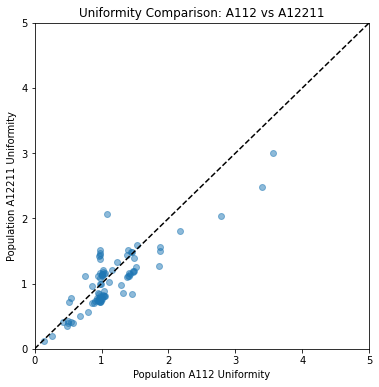

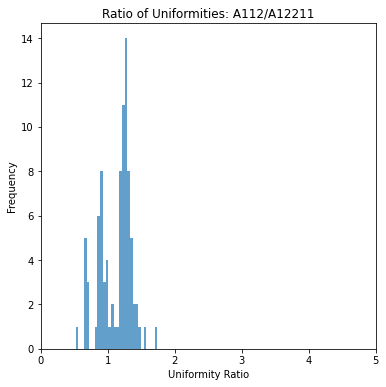

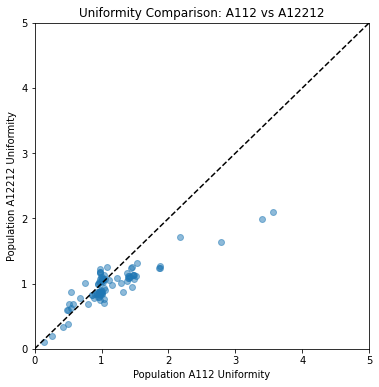

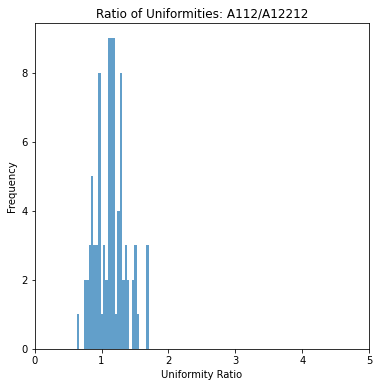

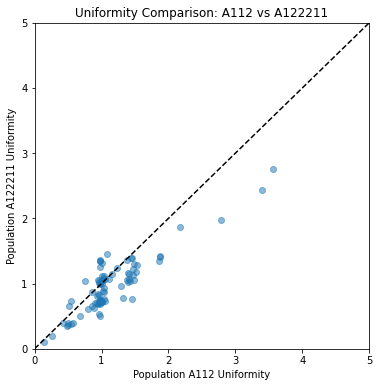

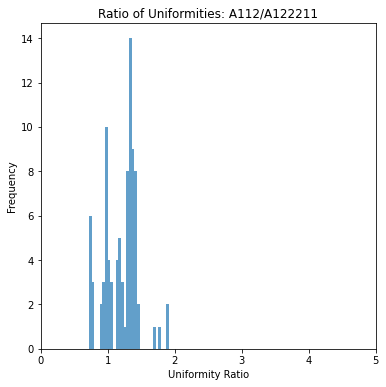

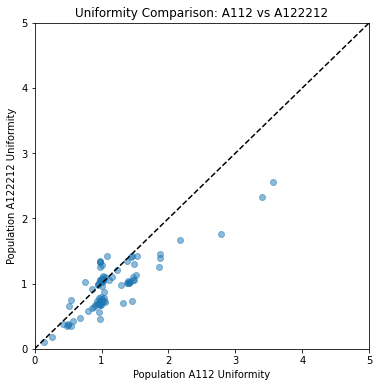

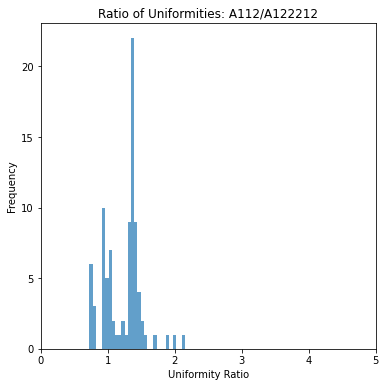

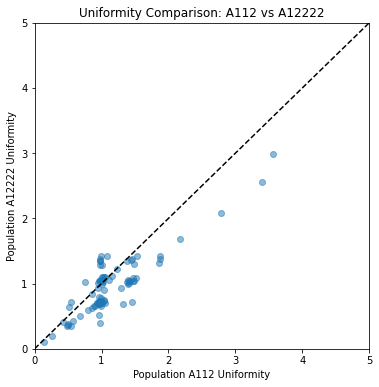

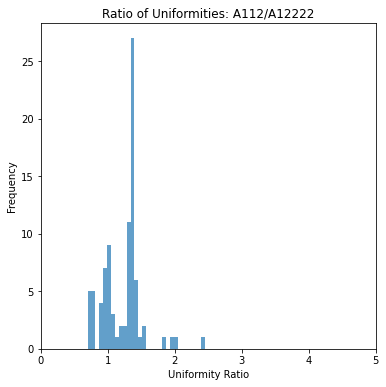

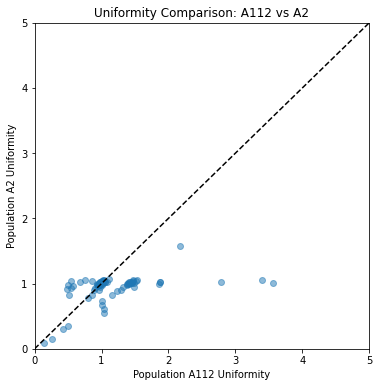

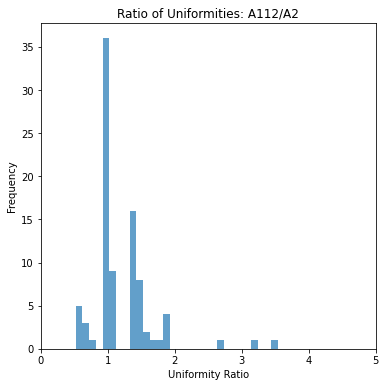

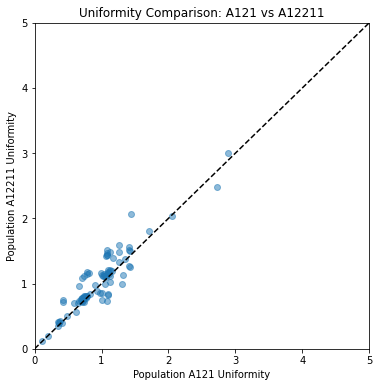

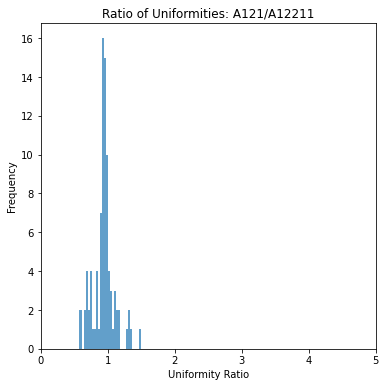

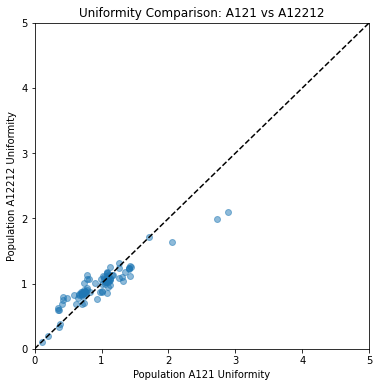

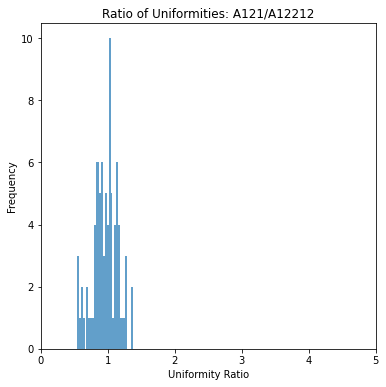

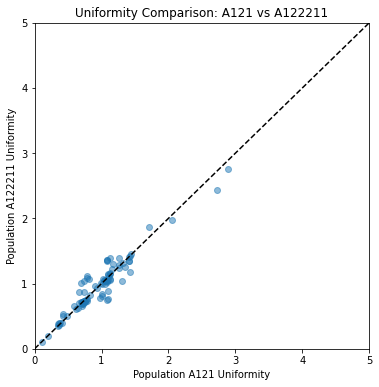

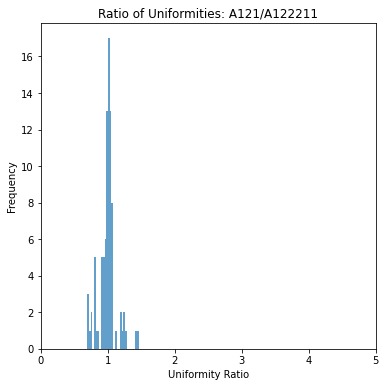

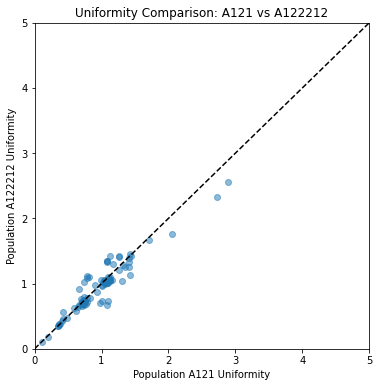

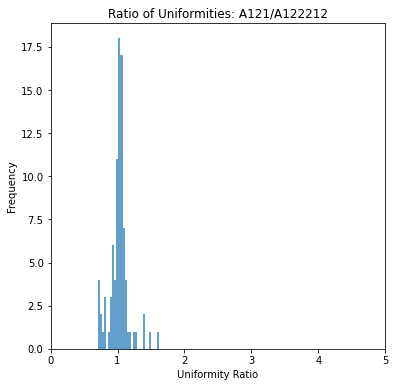

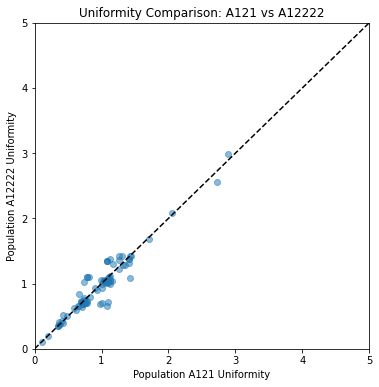

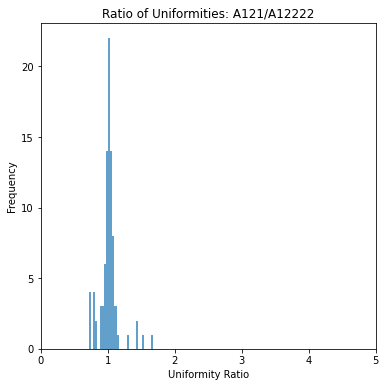

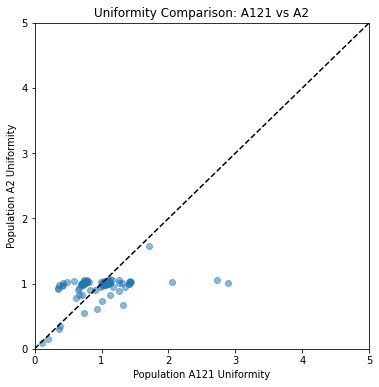

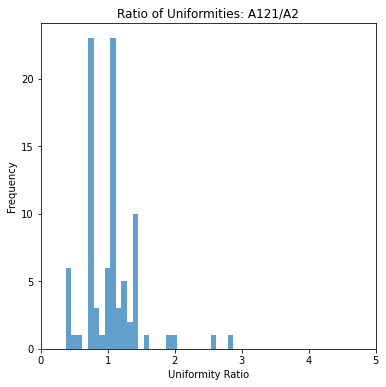

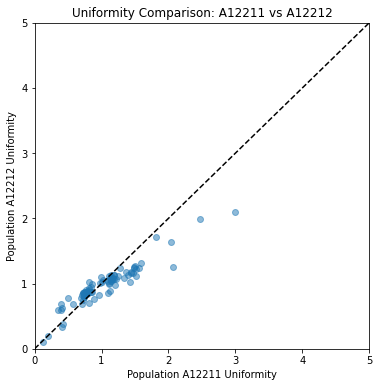

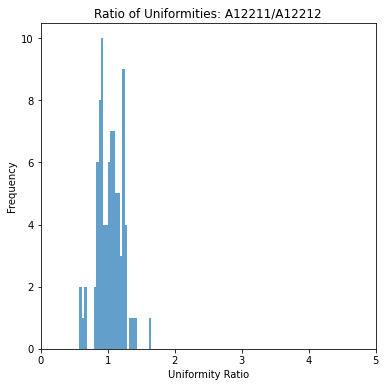

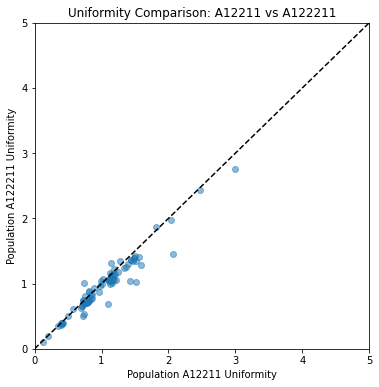

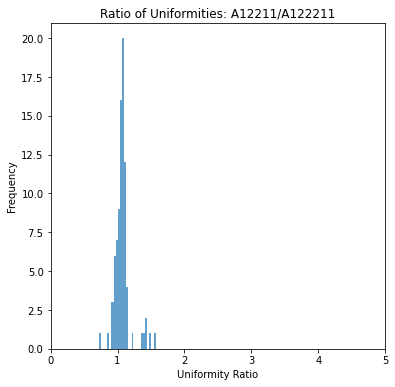

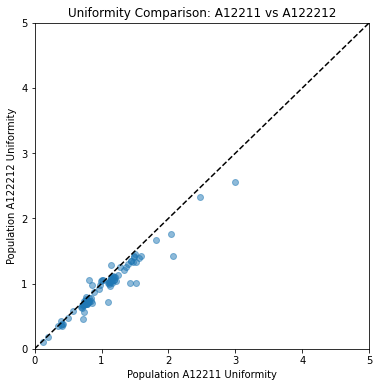

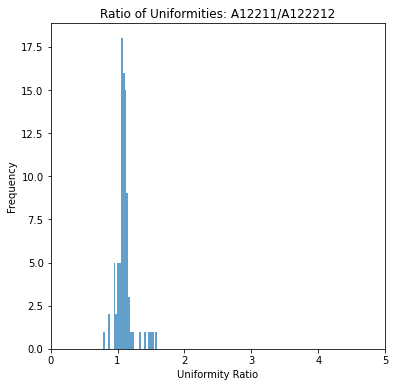

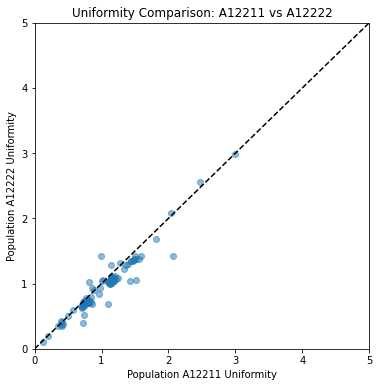

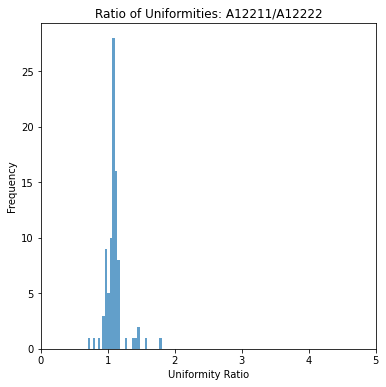

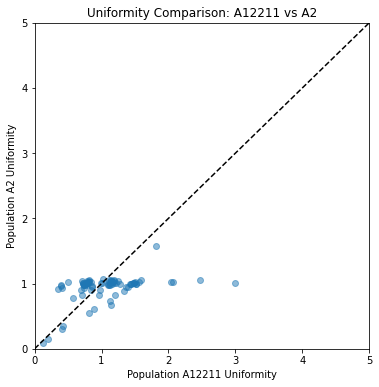

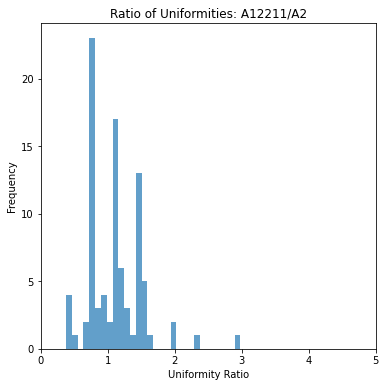

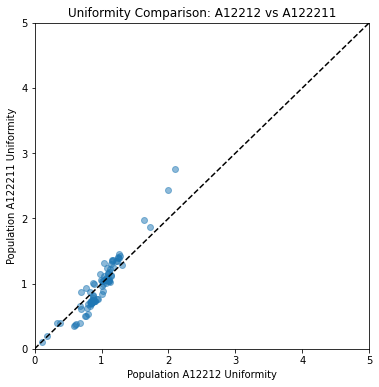

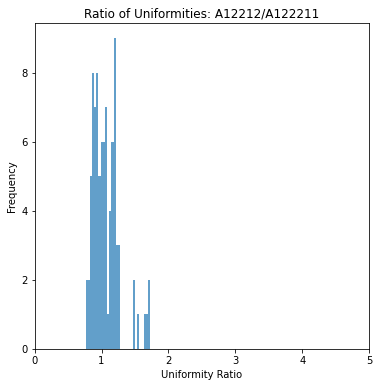

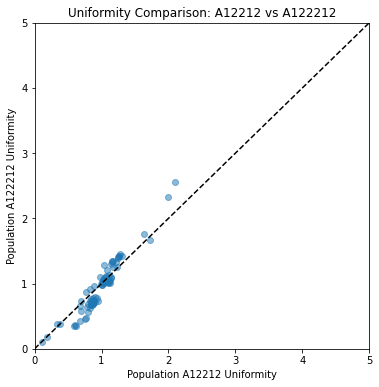

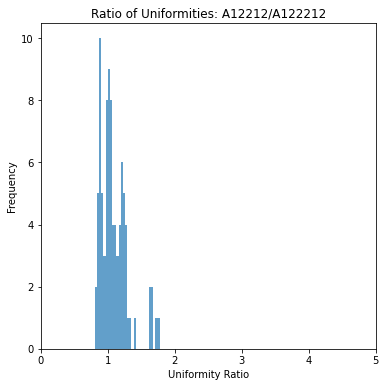

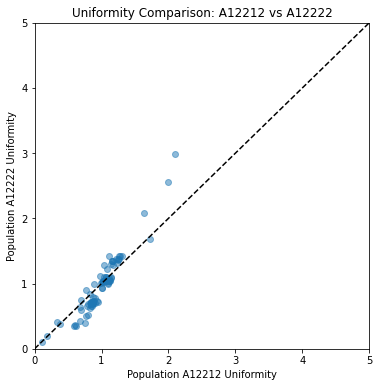

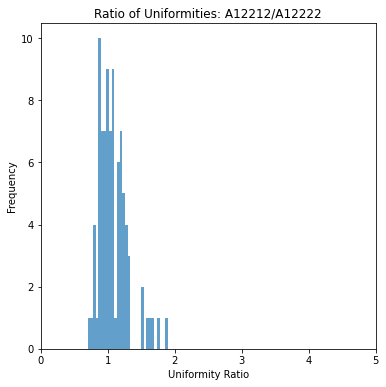

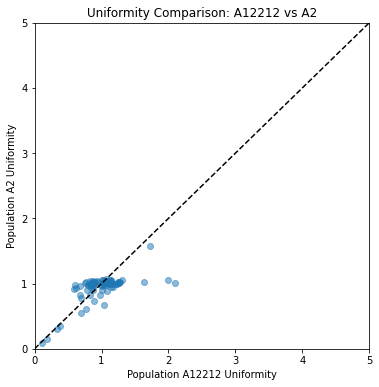

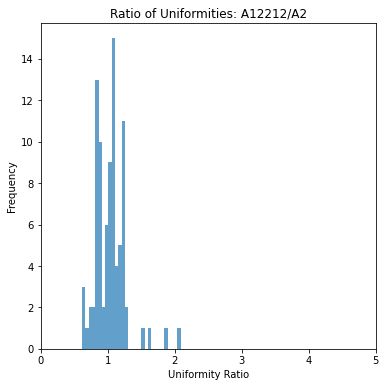

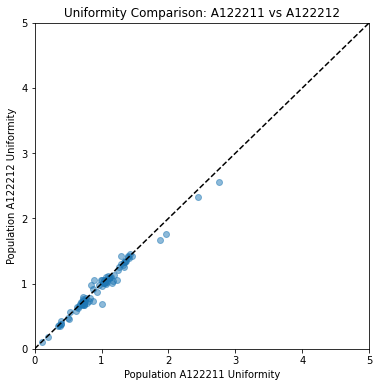

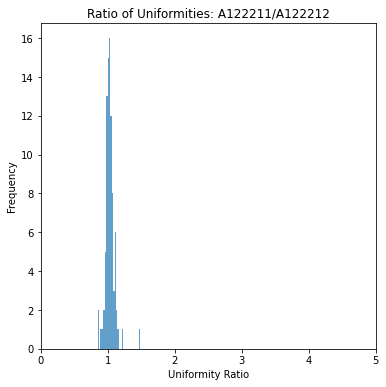

Populations A122211 and A122212 are similar.


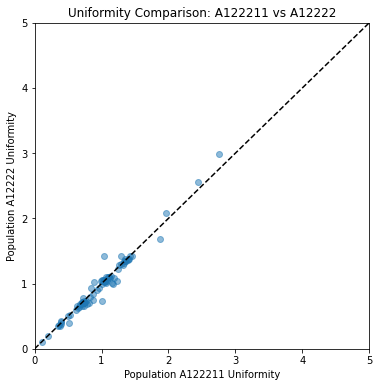

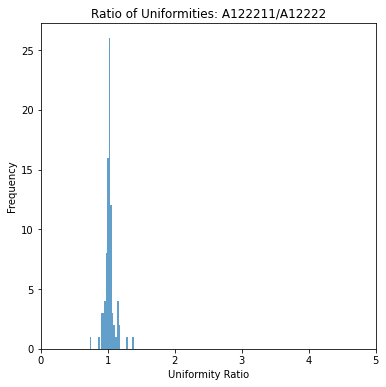

Populations A122211 and A12222 are similar.


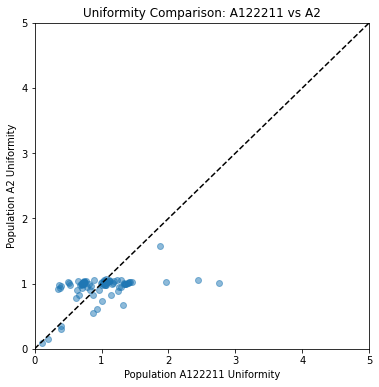

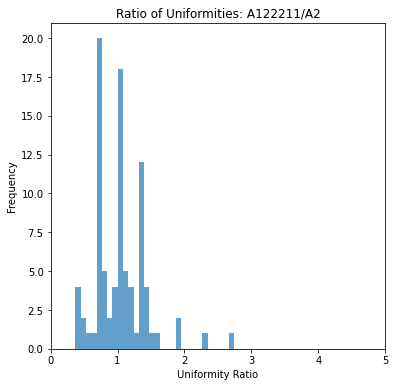

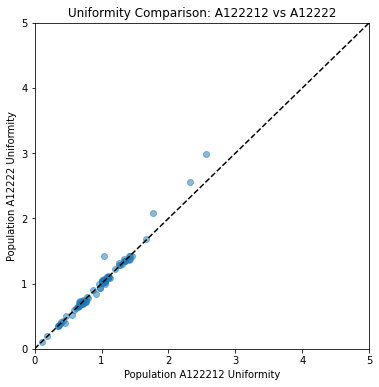

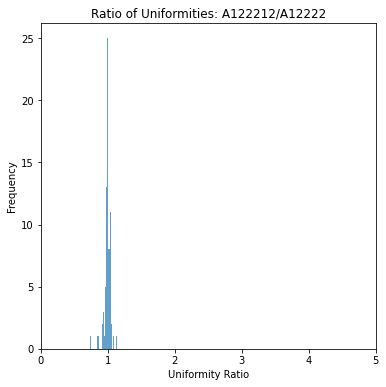

Populations A122212 and A12222 are similar.


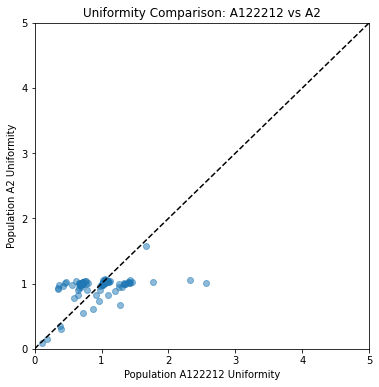

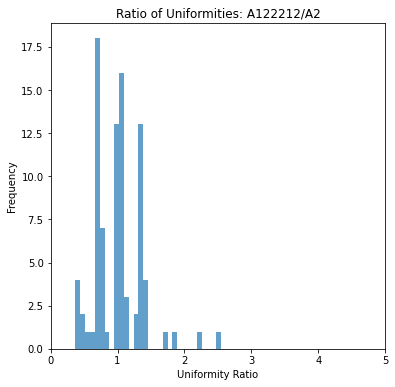

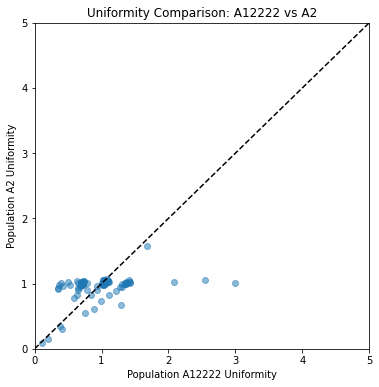

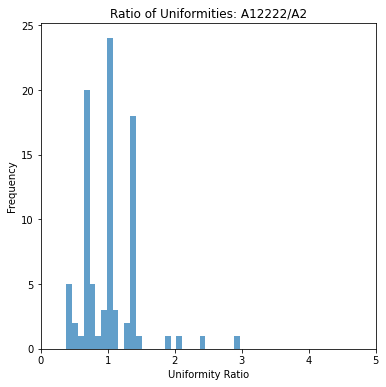

In [54]:
unif_dict, min_dev_pop = make_unif_dict(all_data, reassigned_populations)
similar_populations = find_similar_populations(unif_dict)

In [55]:
similar_populations

[('A1111', 'A1112'),
 ('A1111', 'A112'),
 ('A1112', 'A112'),
 ('A122211', 'A122212'),
 ('A122211', 'A12222'),
 ('A122212', 'A12222')]

In [56]:
# Draw a graph of similar populations
import networkx as nx
def make_similarity_graph(reassigned_populations, similar_populations, min_dev_pop):
    G = nx.Graph()


    #Nodes for all populations even the non-similar ones
    for pop in reassigned_populations:
        if pop not in G:
            if pop == min_dev_pop:
                G.add_node(pop, color='green')  # Highlight normal population
            else:
                G.add_node(pop, color='lightblue')
    G.add_edges_from(similar_populations)

    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G)
    node_colors = [G.nodes[node]['color'] for node in G]
    nx.draw(G, pos, with_labels=True, edge_color='gray', node_size=2000, font_size=15, node_color=node_colors)  
    plt.title("Graph of Similar Populations")
    plt.show()

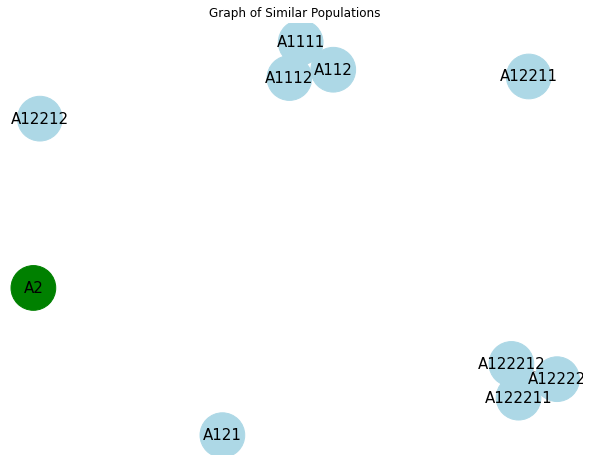

In [57]:
make_similarity_graph(reassigned_populations, similar_populations, min_dev_pop)

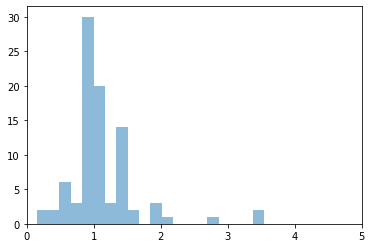

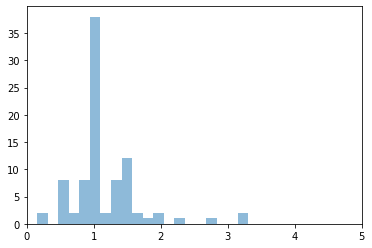

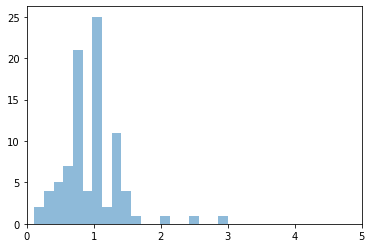

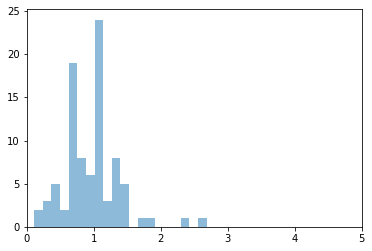

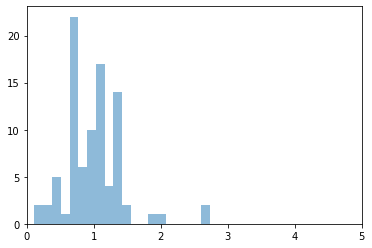

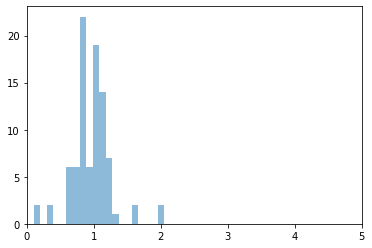

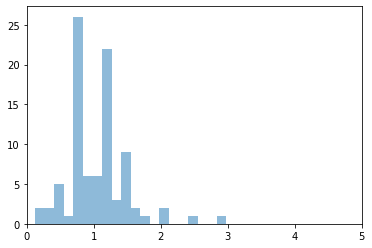

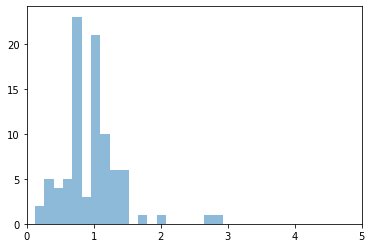

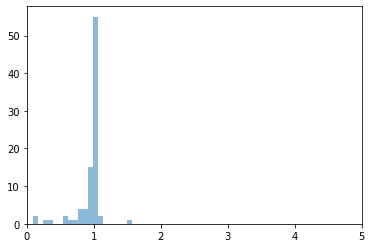

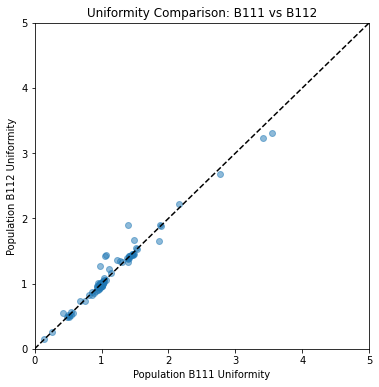

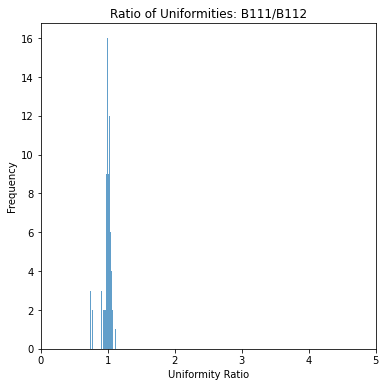

Populations B111 and B112 are similar.


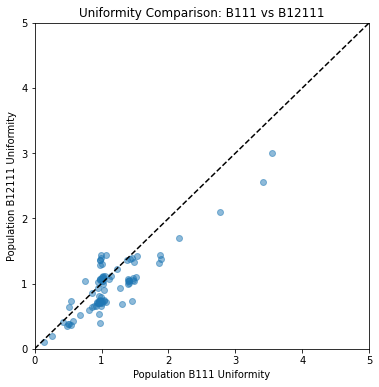

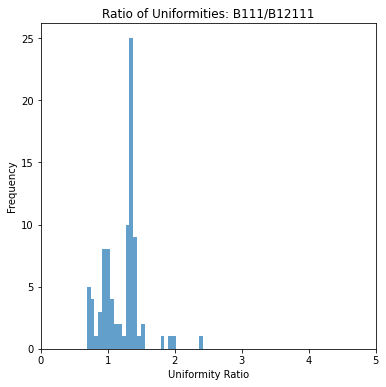

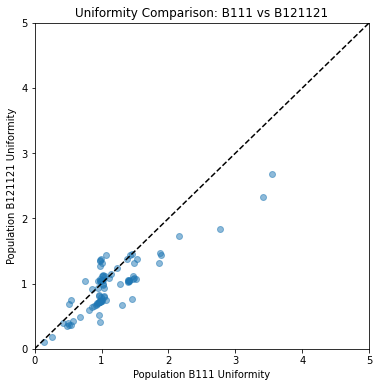

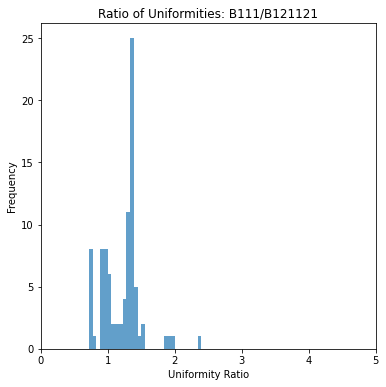

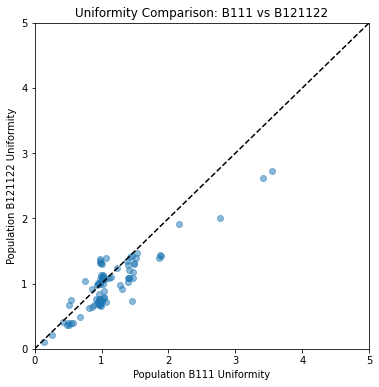

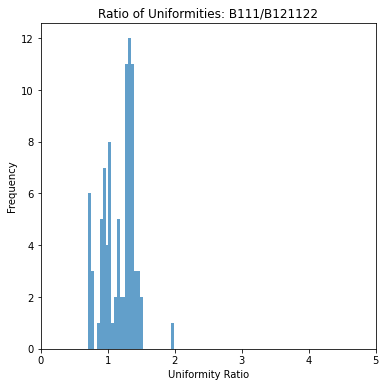

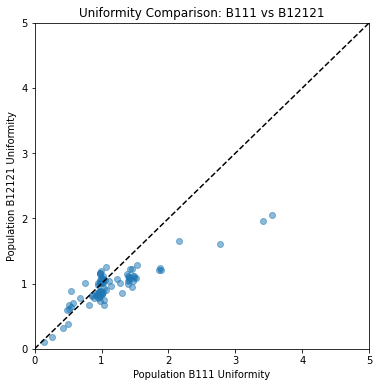

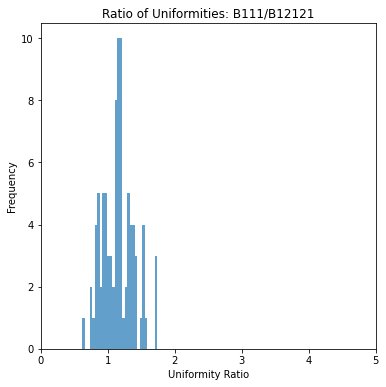

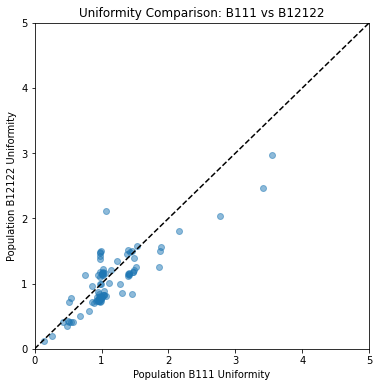

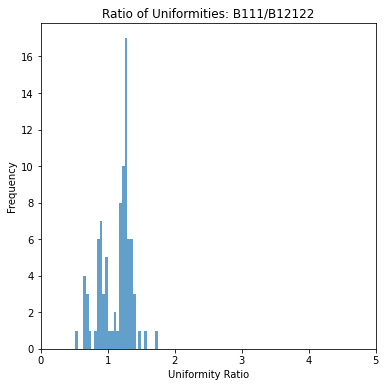

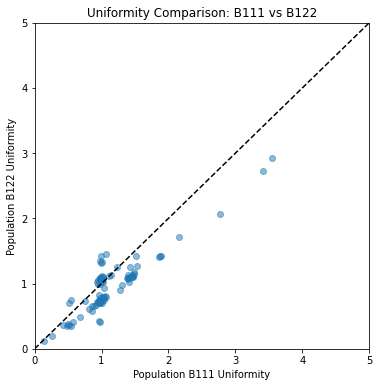

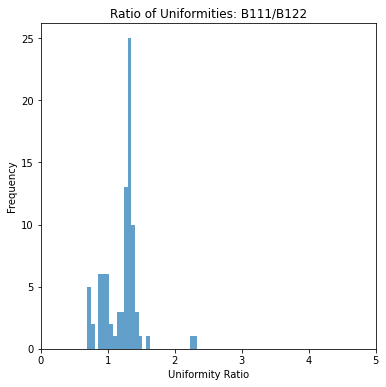

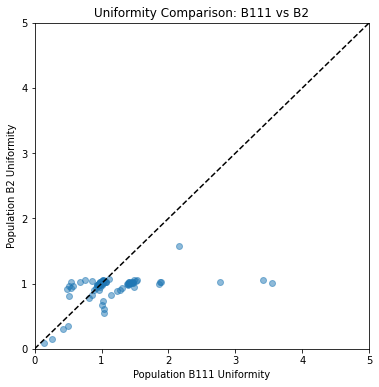

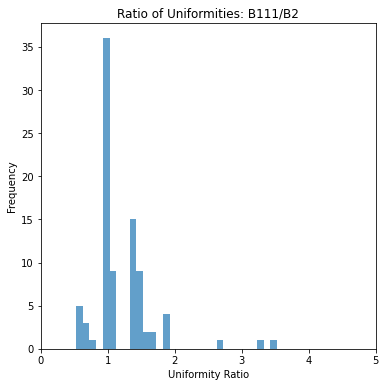

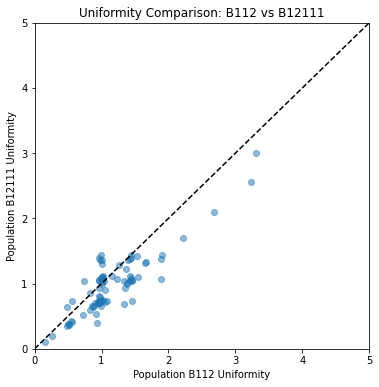

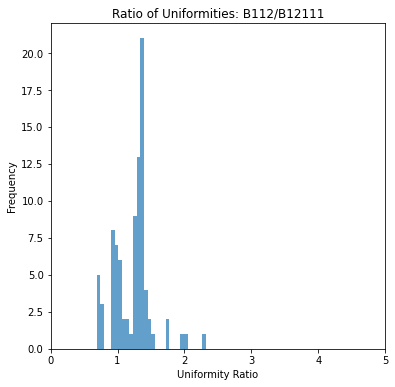

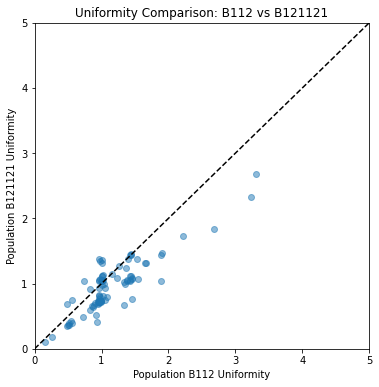

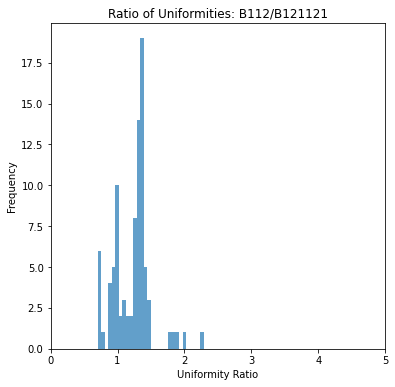

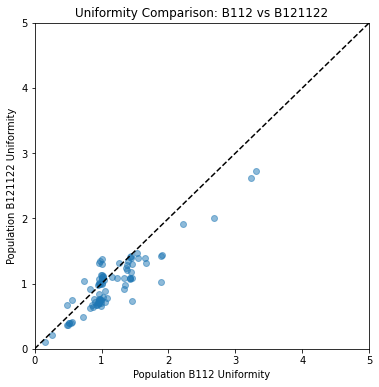

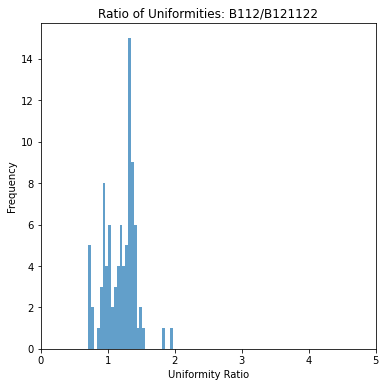

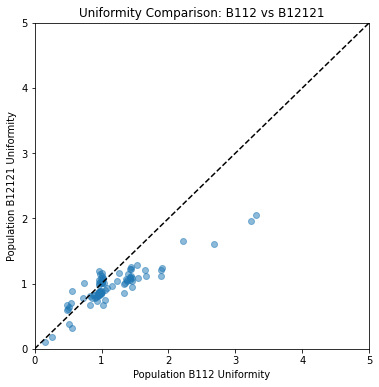

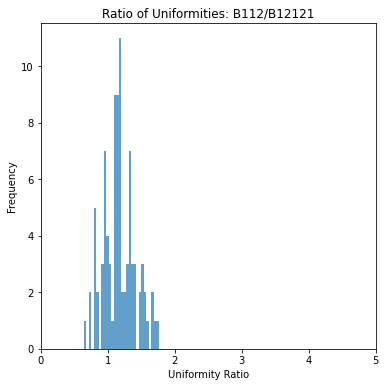

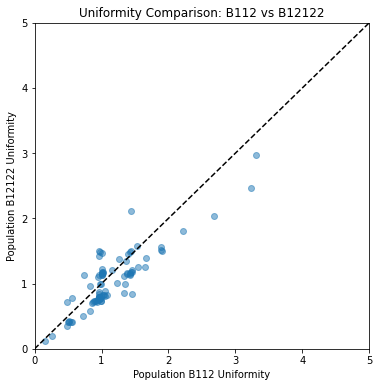

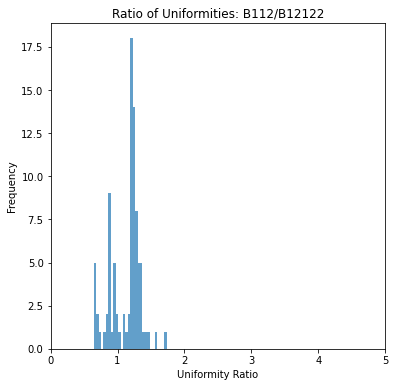

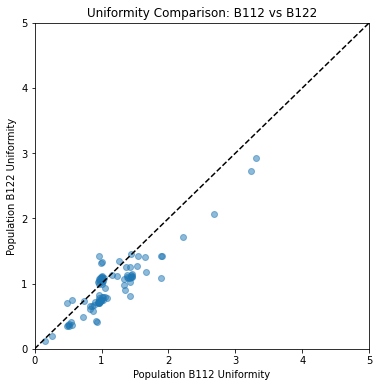

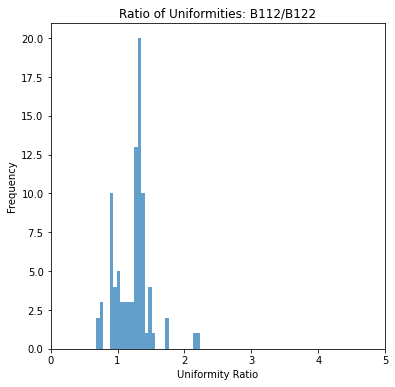

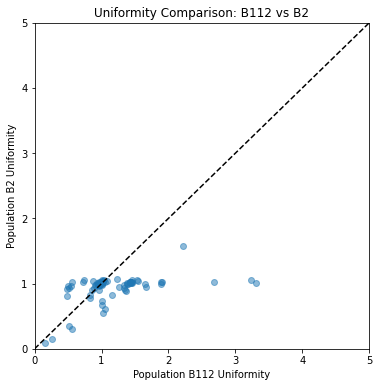

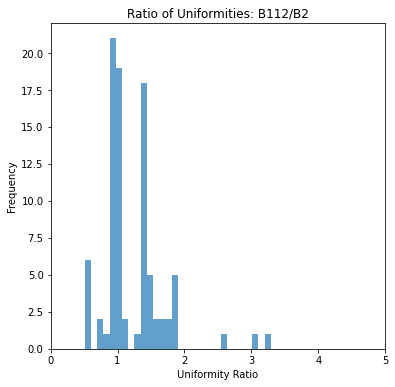

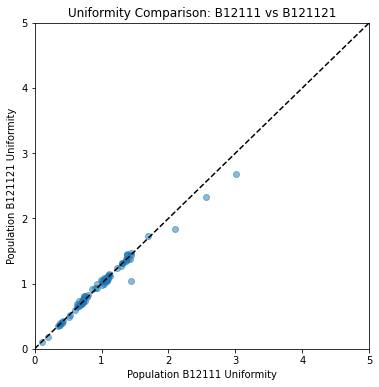

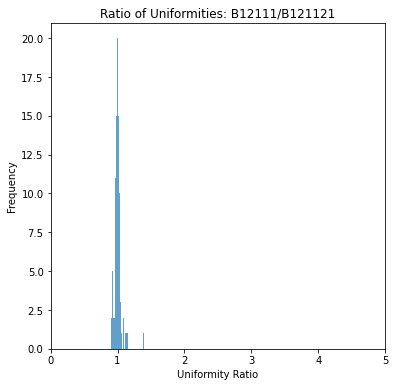

Populations B12111 and B121121 are similar.


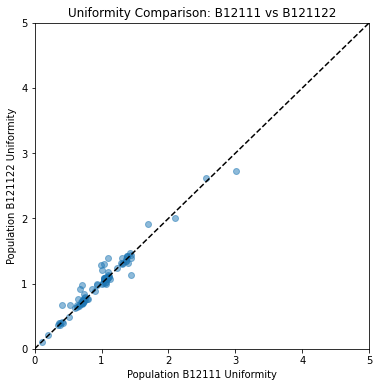

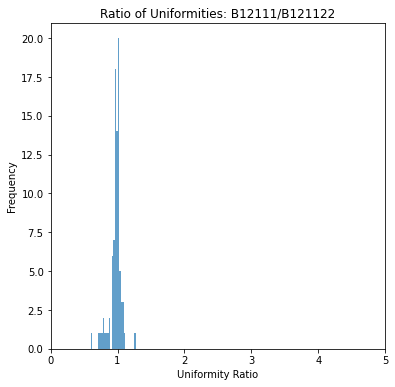

Populations B12111 and B121122 are similar.


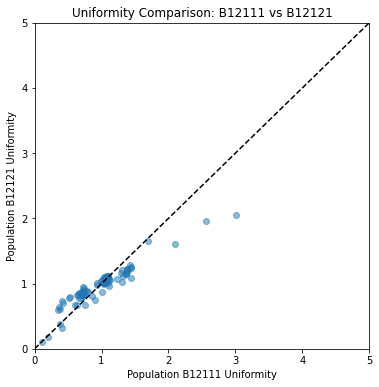

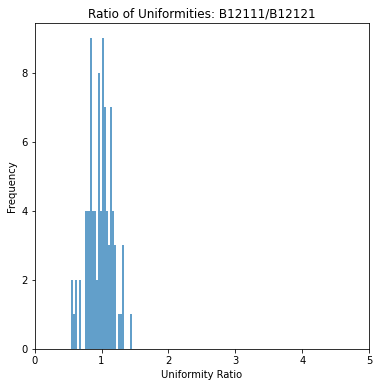

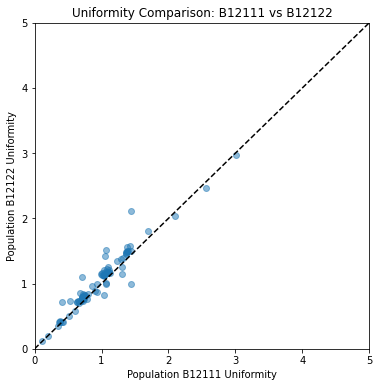

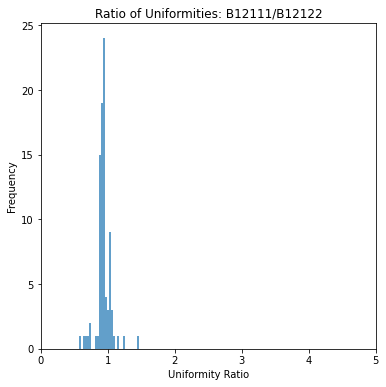

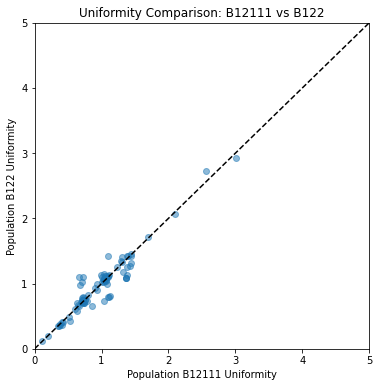

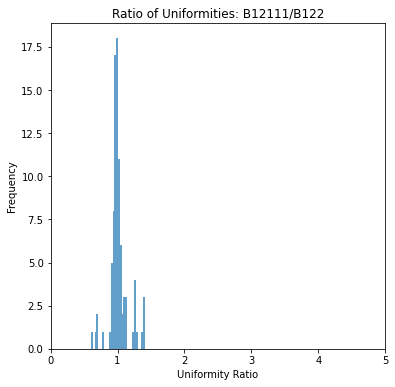

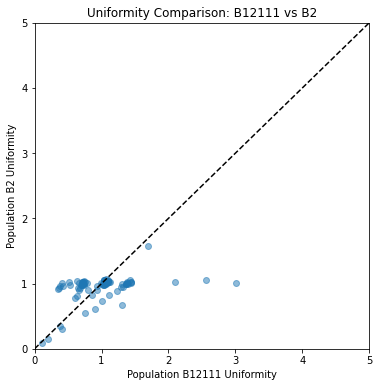

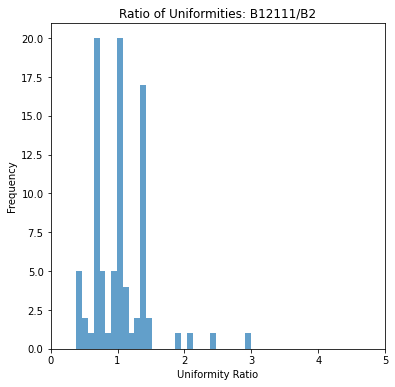

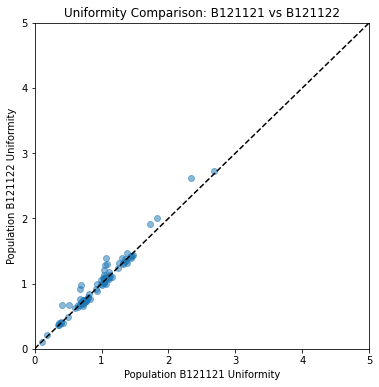

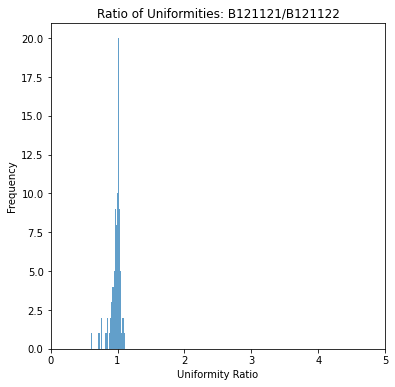

Populations B121121 and B121122 are similar.


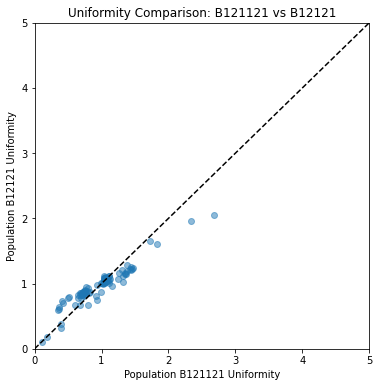

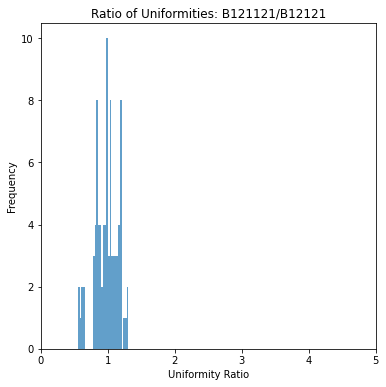

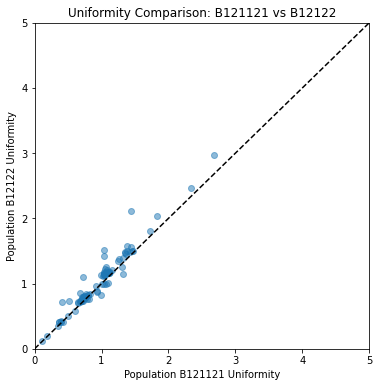

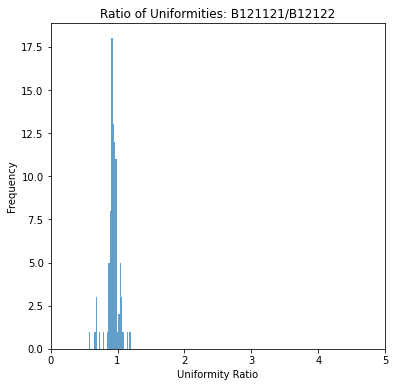

Populations B121121 and B12122 are similar.


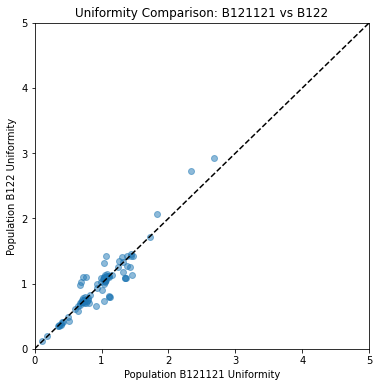

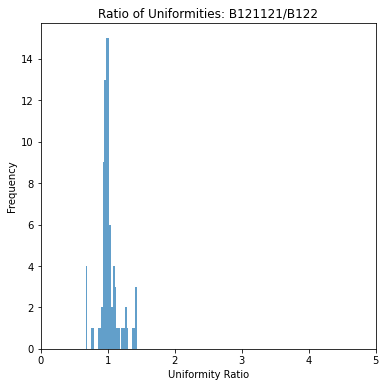

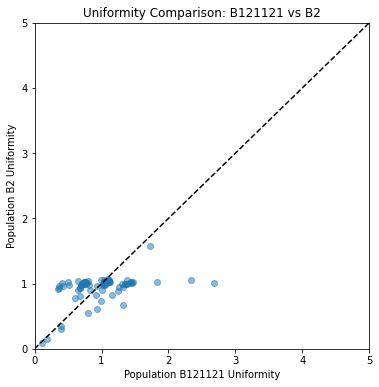

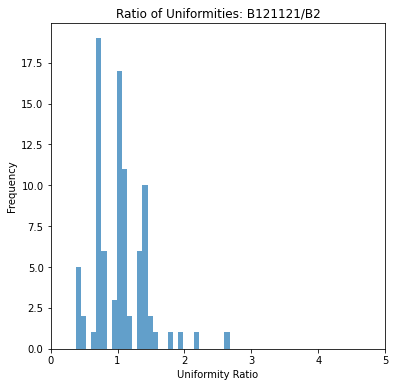

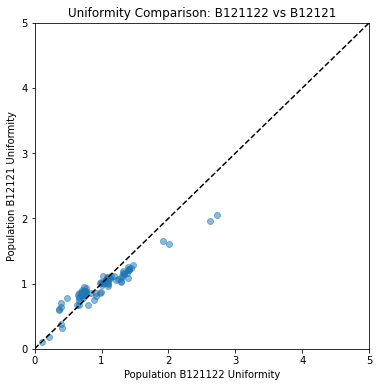

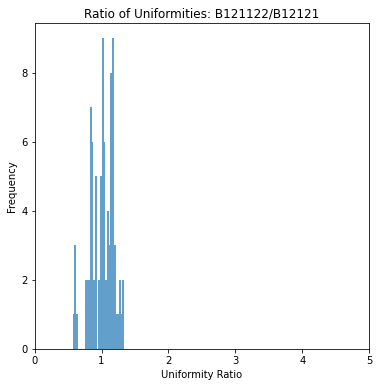

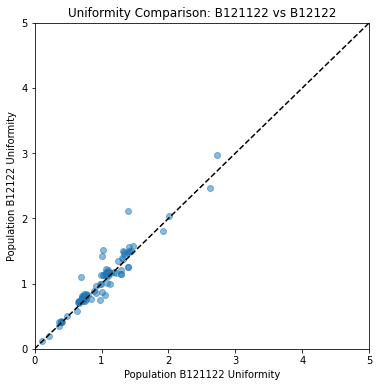

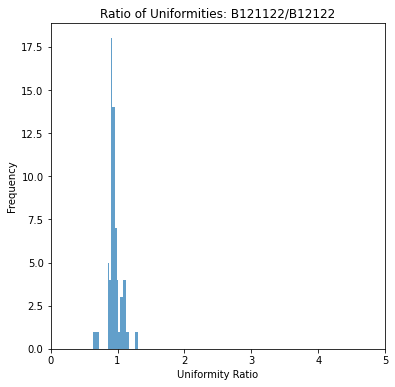

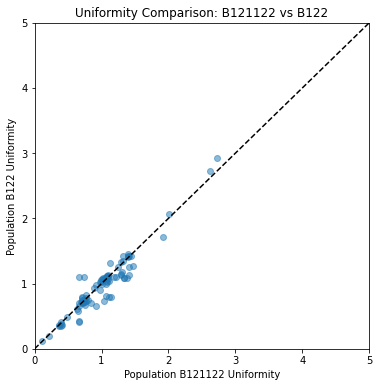

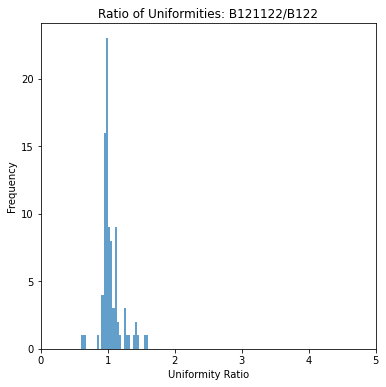

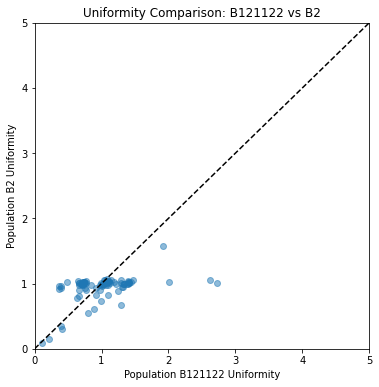

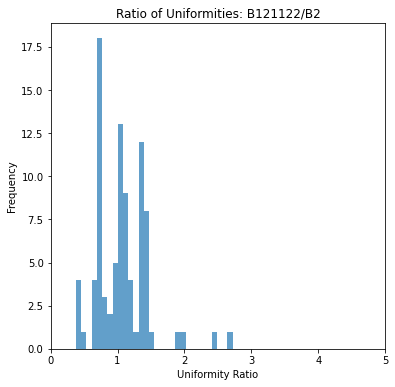

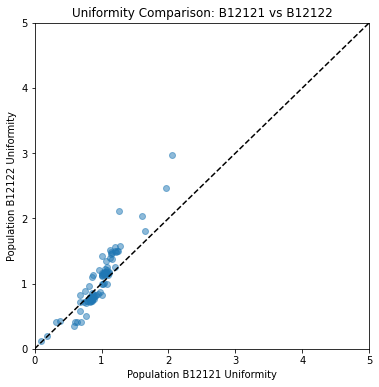

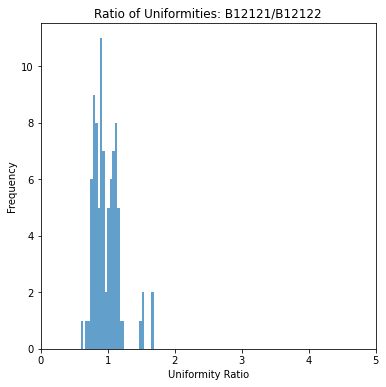

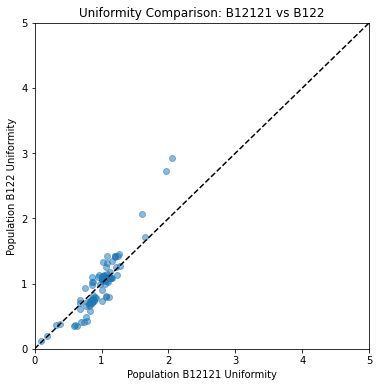

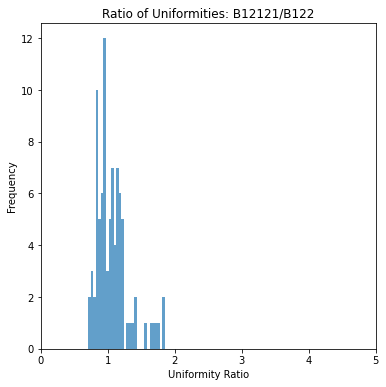

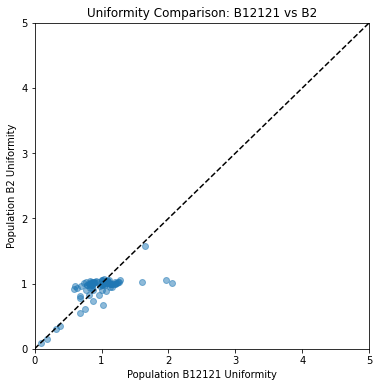

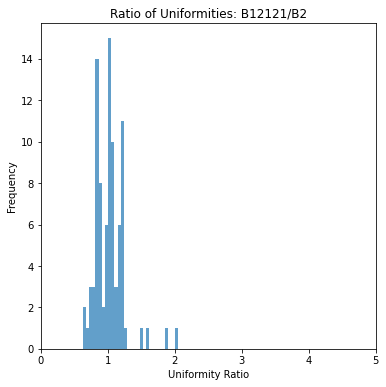

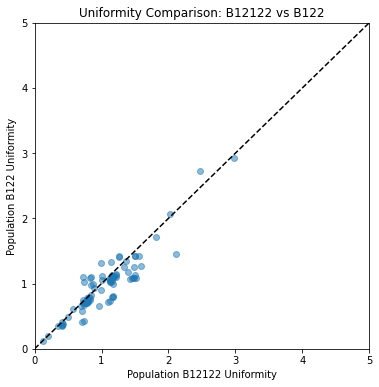

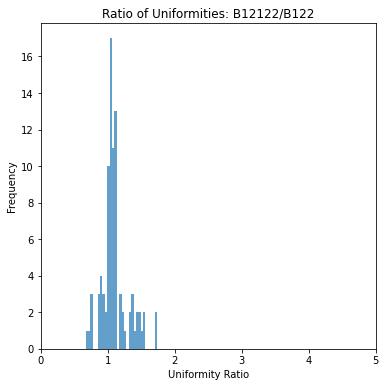

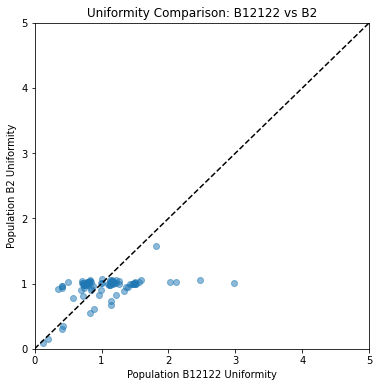

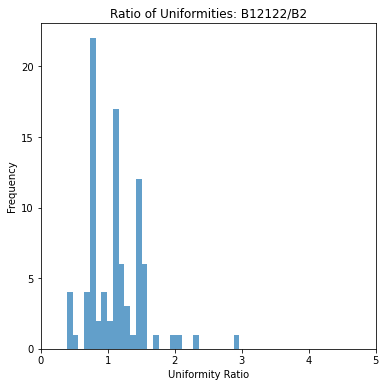

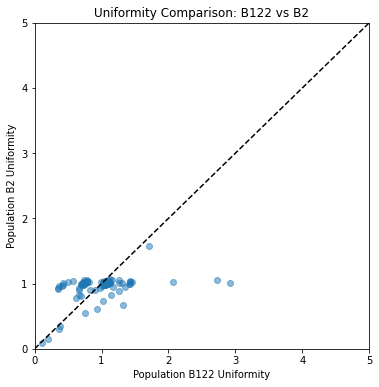

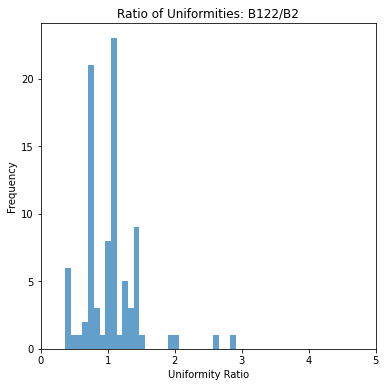

In [58]:
unif_dict_2, min_dev_pop_2 = make_unif_dict(all_data, reassigned_populations_2)
similar_populations_2 = find_similar_populations(unif_dict_2)

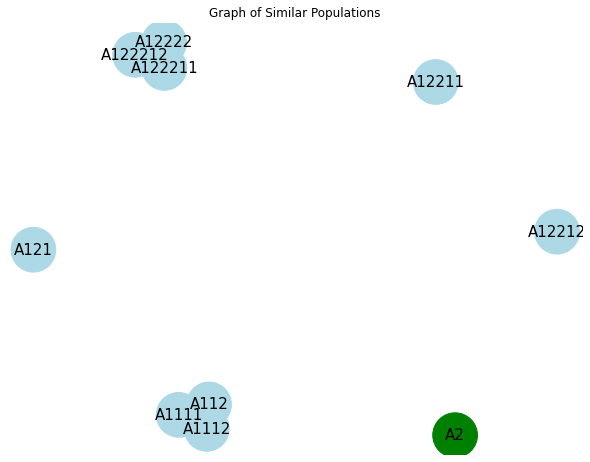

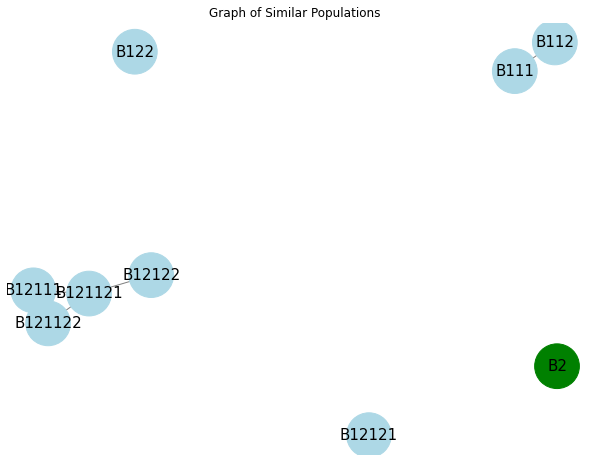

In [59]:
make_similarity_graph(reassigned_populations, similar_populations, min_dev_pop)
make_similarity_graph(reassigned_populations_2, similar_populations_2, min_dev_pop_2)

In [60]:
# Merge similar populations based on similarity graph to get new populations

def merge_similar_populations(reassigned_populations, similar_populations, name="A"):
    """
    Merge similar populations based on similarity graph.
    
    Parameters:
    - reassigned_populations: dictionary of populations with their cells and mult_KV parameters
    - similar_populations: list of tuples indicating similar population pairs
    
    Returns:
    - Dictionary with merged populations
    """
    
    # Create a graph to represent population similarities
    G = nx.Graph()
    for pop in reassigned_populations:
        if pop not in G:
            G.add_node(pop, color='lightblue')
    G.add_edges_from(similar_populations)

    
    # Find connected components in the graph (each component represents populations to merge)
    components = list(nx.connected_components(G))
    
    merged_populations = {}
    
    for i, component in enumerate(components):
        merged_cells = []
        
        for pop in component:
            merged_cells.extend(reassigned_populations[pop]["cells"])
        
        merged_pop_name = name+"M" + str(i+1)
        merged_populations[merged_pop_name] = {"cells": merged_cells}

    return merged_populations

In [61]:
A_merged = merge_similar_populations(reassigned_populations, similar_populations, name="A")
B_merged = merge_similar_populations(reassigned_populations_2, similar_populations_2, name="B")

In [62]:
print_overlap_matrix(A_merged, B_merged, "A_merged", "B_merged")


Overlap Matrix (A_merged rows vs B_merged cols):
Pop          BM1     BM2     BM3     BM4     BM5
AM1          367       0       3       0       3
AM2            0       3       0      80       0
AM3            0      39       0       0       0
AM4            1       4      52       0       0
AM5            0     263       1       1       0
AM6            0       0       0       0    1716


In [63]:
print_overlap_matrix(A_merged, reassigned_populations, "A_merged", "A")



Overlap Matrix (A_merged rows vs A cols):
Pop        A1111   A1112    A112    A121  A12211  A12212 A122211 A122212  A12222      A2
AM1           43     107     223       0       0       0       0       0       0       0
AM2            0       0       0      83       0       0       0       0       0       0
AM3            0       0       0       0      39       0       0       0       0       0
AM4            0       0       0       0       0      57       0       0       0       0
AM5            0       0       0       0       0       0      49      84     132       0
AM6            0       0       0       0       0       0       0       0       0    1716


In [64]:
print_overlap_matrix(B_merged, reassigned_populations_2, "B_merged", "B")


Overlap Matrix (B_merged rows vs B cols):
Pop         B111    B112  B12111 B121121 B121122  B12121  B12122    B122      B2
BM1          224     144       0       0       0       0       0       0       0
BM2            0       0     129      91      50       0      39       0       0
BM3            0       0       0       0       0      56       0       0       0
BM4            0       0       0       0       0       0       0      81       0
BM5            0       0       0       0       0       0       0       0    1719


In [88]:
spectral_data = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/spectral_clustering_results.txt", sep="\t")

In [89]:
spectral_data.head()

,cell_id,hierarchical_cluster
0,AAAACCAACCTGATAAC,I1
1,AAAACCAACTTTTGACG,I21
2,AAAACCAATTTCAGTAC,I1
3,AAAACCACTGGCCTTAC,I21
4,AAAACCAGCTTAGATAC,I22


In [90]:
spectral_grps = spectral_data.groupby("hierarchical_cluster")

In [91]:
inter_cluster_names = spectral_data["hierarchical_cluster"].unique()

In [92]:
# Make a population dict for spectral results
inter_dict = {}
for name in inter_cluster_names:
    inter_dict[name] = {"cells": spectral_grps.get_group(name)["cell_id"].tolist()}


In [93]:
print_overlap_matrix(inter_dict, A_merged, "interdigital", "A")


Overlap Matrix (interdigital rows vs A cols):
Pop          AM1     AM2     AM3     AM4     AM5     AM6
I1            16       0       0      18       0    1714
I21          356       2       0       3       0       1
I22            1      81      39      36     265       1


In [94]:
print_overlap_matrix(inter_dict, reassigned_populations, "interdigital", "A")


Overlap Matrix (interdigital rows vs A cols):
Pop        A1111   A1112    A112    A121  A12211  A12212 A122211 A122212  A12222      A2
I1             7       0       9       0       0      18       0       0       0    1714
I21           36     106     214       2       0       3       0       0       0       1
I22            0       1       0      81      39      36      49      84     132       1
